# 🧾 Lab 04c: Ask Your Books: Evaluating Text-to-SQL Analytics

## Supplemental lab after Module 04 (Evaluating Retrieval-Augmented Systems)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/04c-text-to-sql-analytics-lab.ipynb)

| | |
|---|---|
| ⏱️ **Time** | 85–100 min core, plus optional 🏆 challenges |
| 🎚️ **Level** | Intermediate–advanced. You read SQL; you don't need to write much |
| 🔑 **Keys needed** | None. Fully offline: SQLite in memory, recorded model outputs, fixed seeds. Optional: an OpenAI or Anthropic key to let a real model write the SQL |
| 🧰 **Tools** | `sqlite3` (Python standard library), `pandas`, `matplotlib` |
| 💻 **You'll code** | Exercises 2A (a result comparator), 3A (a fuzzer), 6A (a consistency check). Each has a safe fallback, so *Run All* always works |
| 🏁 **You'll leave with** | A five-layer evaluation for any "ask your data" feature, a way to audit the answer key, and a migration verdict you can defend |

### 🎬 The hook

> **#ledgerly-ask-launch** · **Dev (PM):** Bad news. The model behind **Ledgerly Ask** retires on **14 January 2027**, so we have to migrate. The replacement (**v2**) scores **64%** on our CI golden set; the current model (**v1**) scores **80%**. CI says 🛑 **BLOCK**. Should I ask the provider for an extension? 😬

Would you block the migration? Most engineers would: a 16-point drop on a number-answering feature looks disqualifying. By Task 4 you'll know that the CI number measured something other than correctness, and which model actually gives owners the right numbers.

> 📅 **Not hypothetical.** Model providers retire models on announced dates. Several widely used models shut down on 14 January 2027, so every product built on them faces this migration whether or not the eval is ready.

## Overview

**Text-to-SQL** (also called **NL2SQL**): a model turns a plain-English question ("how much did we spend with Marco Diaz in Q2?") into a SQL query, the query runs on the customer's books, and the result becomes the answer. In this design the model never invents the number; the database computes it. That makes the SQL the thing to evaluate, and SQL turns out to be hard to grade.

You'll grade the same 50 golden questions five ways. Each layer catches something the previous one missed, and the v1-vs-v2 gap changes sign along the way:

- **Task 1: Exact match.** Compare the SQL text. Learn what text comparison actually measures.
- **Task 2: Execution accuracy.** Run both queries and compare the results. You'll write the comparator.
- **Task 3: Test-suite accuracy.** Run them on many databases, not one. You'll write a fuzzer.
- **Task 4: Audit the answer key.** The plot twist.
- **Task 5: Ambiguous questions.** Some questions have more than one right answer.
- **Task 6: No gold at all.** Find bugs in production with consistency checks. You'll write one.
- **Task 7: The decision.** A paired comparison and a migration verdict.

<details><summary>📖 <b>Jargon decoder: 24 terms this lab uses (click to open)</b></summary>

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **Text-to-SQL / NL2SQL** | A model writes a SQL query from a natural-language question; the database computes the answer | Everywhere |
| **Golden set** | A fixed list of test questions with agreed answers, used to score every version | Task 1 |
| **Gold SQL / answer key** | The reference query for a golden question. Its result is treated as the right answer | Task 1 |
| **Exact match (EM)** | Pass if the predicted SQL text equals the gold SQL text (after trimming spaces and case) | Task 1 |
| **Execution accuracy (EX)** | Pass if the predicted query's *result* equals the gold query's result on one database | Task 2 |
| **Result set** | The rows a query returns, e.g. `[(4200.0,)]` (one row, one column) | Task 2 |
| **Comparator** | The function that decides whether two result sets count as "the same answer" | Task 2 |
| **CTE** | A `WITH name AS (...)` block: a named sub-query, a style choice that changes the text but not the result | Task 1 |
| **Test-suite accuracy** | Pass only if the results match on *every* database in a suite of varied databases (Zhong et al., 2020) | Task 3 |
| **Fuzzer** | Code that copies a database and injects one kind of edge case (voided entries, month-end timestamps…) | Task 3 |
| **Lucky pass** | A wrong query that matches the gold on the test database because the data that would expose it isn't there | Task 3 |
| **Annotation error** | A mistake in the answer key itself | Task 4 |
| **Report engine** | The product's existing, audited report code (P&L, vendor spend). In this lab it's the trusted source for "the right number" | Task 4 |
| **Reading (interpretation)** | One valid way to understand an ambiguous question | Task 5 |
| **Metric glossary (semantic layer)** | Written definitions of business terms ("spend = bills + expenses − credits, posted only") that the model must follow | Task 5 |
| **Metamorphic test** | Check a *relation* between answers instead of each answer: Q3 total must equal July + Aug + Sep. Needs no gold | Task 6 |
| **Discordant pair** | A question one model got right and the other got wrong. Only these say anything about which is better | Task 7 |
| **McNemar test / Wilson CI** | A paired significance test on discordant pairs / a confidence interval for a pass rate (both from Lab 05b) | Task 7 |
| **Bill vs bill payment** | A *bill* records what you owe a vendor; a *bill payment* records paying it. Counting both double-counts | Task 2 |
| **Void / draft** | A voided entry was cancelled; a draft was never approved. Neither counts in any total | Task 3 |
| **Vendor credit / refund** | Money a vendor gives back (a credit) or you give a customer back (a refund). It *reduces* spend or revenue | Task 3 |
| **1099 contractor** | A self-employed person you pay for services; US businesses report payments to them on Form 1099-NEC | Task 5 |
| **Accrual vs cash basis** | Accrual counts an expense when the bill arrives; cash counts it when you pay | Task 5 |
| **Fiscal vs calendar quarter** | A company's fiscal year can start in any month (Harbor & Pine's starts 1 Feb), so "Q2" can mean two different date ranges | Task 5 |

</details>

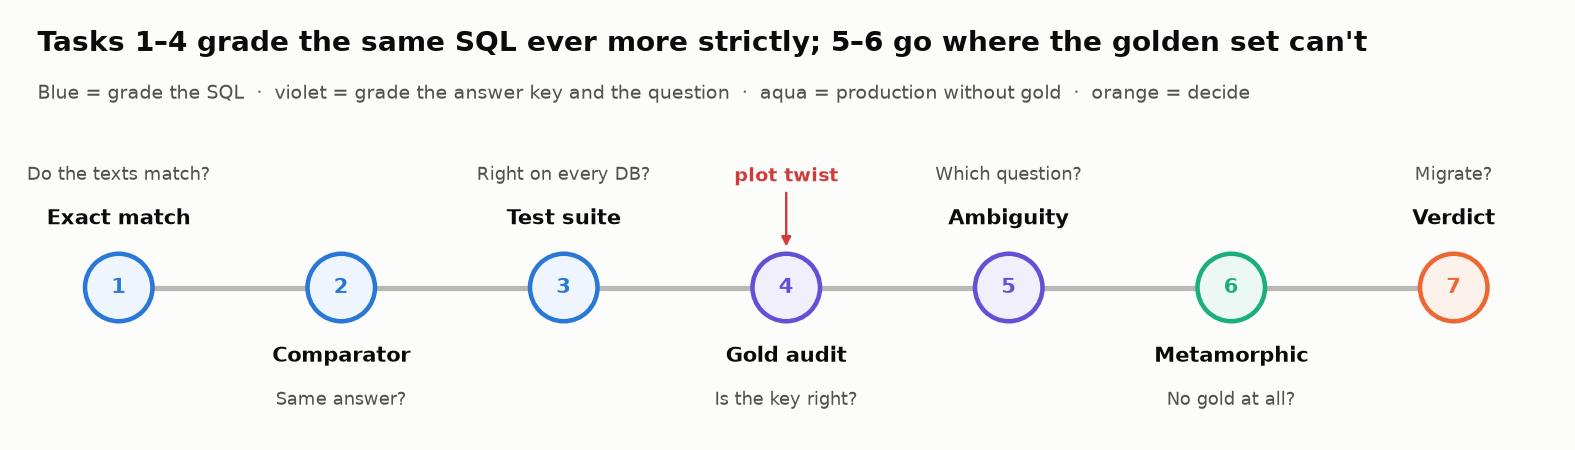

<sub>🖼️ *Each task adds one layer of evaluation and asks one question the previous layer couldn't answer.*</sub>

## Learning Objectives

You will be able to:

1. Explain why **exact match** on SQL text measures style, and **execution accuracy** on one database measures luck as well as correctness.
2. Write and unit-test a **result-set comparator** (cents, row order, column order, errors).
3. Build a **test suite** of fuzzed databases and explain how it removes lucky passes (and amplifies a wrong answer key).
4. **Audit an answer key** against an independent source of truth, and recognize when gold errors are **correlated** with one model.
5. Grade **ambiguous** questions against a set of acceptable readings and score whether the answer **states its assumption**.
6. Write a **metamorphic** consistency check that finds bugs without gold, and name its blind spot.
7. Make a **paired**, evidence-based model-migration decision.

## Prerequisites

- Module 04 (retrieval and abstention) and Lab 03's idea that a comparator is part of the metric. Lab 05b's paired comparison helps in Task 7 but is re-explained.
- Reading basic SQL: `SELECT`, `WHERE`, `JOIN`, `GROUP BY`, `SUM`. You won't write queries from scratch.
- No accounting background: each bookkeeping term is defined where it first matters (and in the decoder above).

## Estimated Time

**85–100 minutes** for the core lab; 🏆 challenges add 20–45 minutes.

| Part | Tasks | Time |
|---|---|---|
| Setup | Environment and Setup, Scenario | 8 min |
| Grade the SQL | 1–3 | 35 min |
| Grade the answer key and the question | 4–5 | 25 min |
| Grade production, then decide | 6–7 | 20 min |

## Environment and Setup

1. Run the **imports** cell. Nothing to install.
2. Run the **🎨 Lab kit** cell. It defines `insight()`, `tiles()`, `verdict()` and the chart theme.
3. Run the **🧰 Lab harness** cell. It builds Harbor & Pine's books in an in-memory SQLite database, loads the golden set and the SQL each model wrote, and defines the fuzzers and reference solutions. Peek if you're stuck, but try each exercise first.

> 💡 **Why recorded outputs?** Real models answer a little differently on every call (Lab 05b), which would give every learner different numbers. Here each model's SQL is **recorded** once, so the whole class sees the same results. The optional section after Task 7 lets a real model write the SQL instead.

> 🧠 **How the exercises work:** each **🧠 Your Turn** cell holds a TODO, and the ✅ check cell after it tests your code. If it isn't finished or disagrees with the reference, the check explains why and switches to the reference, so later tasks still run.

In [ ]:
# Everything below ships with Google Colab; sqlite3 is part of Python's standard library.
# Running locally? pip install pandas matplotlib
import itertools
import math
import random
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
print("✅ Environment ready")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v1 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()")

In [ ]:
# @title 🧰 Lab harness: Harbor & Pine's books, the golden set, recorded SQL, fuzzers (run me; code is hidden)
# ============================================================
# 🧰 LAB HARNESS: the "infrastructure" for this lab
# ============================================================
# Builds everything you'll USE but don't need to write:
#   1. make_demo_db()   the CI demo database: one year of Harbor & Pine Coffee Co.'s books (sqlite, in memory)
#   2. golden           the 50-question golden set CI scores against (question, gold SQL, who wrote the gold)
#   3. RECORDED         the SQL each model wrote for each golden question (v1 = incumbent, v2 = candidate)
#   4. run_sql()        execute SQL safely and return rows (or an error string)
#   5. FUZZERS          functions that copy the demo DB and inject one kind of edge case
#   6. report_engine()  the books' audited report engine: the "trusted number" for a question (Task 4)
#   7. ambiguous / production question sets for Tasks 5 and 6
#   8. Reference solutions (names start with _reference_) used as safety nets for the exercises.
# Everything is generated from fixed seeds, so the whole class sees the same numbers.
# ============================================================
import calendar as _cal
import datetime as _dt
import itertools as _it
import math
import random as _random
import re as _re
import sqlite3

import pandas as pd

AS_OF = "2026-10-15"            # "today" in the books (stored in company.as_of)
FY_START_MONTH = 2              # Harbor & Pine's fiscal year starts 1 February

_ACCOUNTS = [  # (id, name, type)
    (1, "Coffee Sales", "Income"), (2, "Wholesale Sales", "Income"), (3, "Merch Sales", "Income"),
    (10, "Green Coffee", "COGS"), (11, "Packaging", "COGS"),
    (20, "Rent", "Expense"), (21, "Payroll", "Expense"), (22, "Contract Labor", "Expense"),
    (23, "Utilities", "Expense"), (24, "Marketing", "Expense"), (25, "Software", "Expense"),
    (26, "Repairs & Maintenance", "Expense"), (27, "Equipment Rental", "Expense"), (29, "Meals", "Expense"),
    (40, "Checking", "Asset"), (41, "Accounts Receivable", "Asset"), (50, "Accounts Payable", "Liability"),
]
_VENDORS = [  # (id, name, is_1099, account_id, (low, high) amount, bills per month, kind)
    (1, "Verde Importers", 0, 10, (900, 2600), 2, "bill"),
    (2, "Mercato Packaging", 0, 11, (180, 620), 2, "bill"),
    (3, "Pine Street Properties LLC", 0, 20, (4200, 4200), 1, "bill"),
    (4, "Brightwage Payroll", 0, 21, (6800, 9400), 2, "expense"),
    (5, "Tidewater Staffing Inc.", 0, 22, (3000, 6000), 1, "bill"),
    (6, "Marco Diaz", 1, 22, (320, 880), 2, "bill"),
    (7, "Ana Sousa Bookkeeping", 1, 22, (450, 450), 1, "bill"),
    (8, "Rivera Plumbing", 1, 26, (140, 980), 1, "bill"),
    (9, "Lena Park Design", 1, 24, (600, 2400), 1, "bill"),
    (10, "Harborlight Utilities", 0, 23, (380, 760), 1, "bill"),
    (11, "Cloudtill POS", 0, 25, (89, 89), 1, "expense"),
    (12, "Coastal Equipment Rentals", 0, 27, (210, 540), 1, "bill"),
    (13, "Mercato Market", 0, 29, (25, 140), 3, "expense"),
    (14, "Gulls & Grain Print Shop", 0, 24, (120, 480), 1, "expense"),
]
_CUSTOMERS = [(1, "Driftwood Cafe"), (2, "Saltmarsh Grocery"), (3, "Ferry Kiosk"), (4, "Lighthouse Inn")]

_SCHEMA = """
CREATE TABLE company (name TEXT, as_of TEXT, fiscal_year_start_month INTEGER);
CREATE TABLE accounts (account_id INTEGER PRIMARY KEY, name TEXT, type TEXT);
CREATE TABLE vendors (vendor_id INTEGER PRIMARY KEY, name TEXT, is_1099 INTEGER);
CREATE TABLE customers (customer_id INTEGER PRIMARY KEY, name TEXT);
CREATE TABLE transactions (
  txn_id INTEGER PRIMARY KEY, txn_date TEXT, txn_type TEXT, account_id INTEGER, vendor_id INTEGER,
  customer_id INTEGER, amount REAL, status TEXT, doc_number TEXT, ref_txn_id INTEGER, memo TEXT);
"""
SCHEMA_DOC = """company(name, as_of, fiscal_year_start_month)
accounts(account_id, name, type)            -- type: Income | COGS | Expense | Asset | Liability
vendors(vendor_id, name, is_1099)           -- is_1099 = 1 for independent contractors (you file a 1099-NEC)
customers(customer_id, name)
transactions(txn_id, txn_date 'YYYY-MM-DD HH:MM:SS', txn_type, account_id, vendor_id, customer_id,
             amount (always positive), status, doc_number, ref_txn_id, memo)
   txn_type: bill | bill_payment | expense | vendor_credit | invoice | payment | sales_receipt | refund
   status:   posted | void | draft"""
GLOSSARY = """Harbor & Pine metric definitions (the 'house rules' every answer must follow):
• spend      = bills + expenses − vendor credits, POSTED only, dated in the period (accrual basis)
• revenue    = invoices + sales receipts − refunds, POSTED only, dated in the period
• a period includes its last day; quarters are calendar quarters unless the question says 'fiscal'"""


def _ts(d, rng, late=False):
    h = 23 if late else rng.randint(8, 17)
    return f"{d.isoformat()} {h:02d}:{59 if late else rng.randint(0, 59):02d}:{rng.randint(0, 59):02d}"


def _months(start=(2025, 11), n=12):
    y, m = start
    for _ in range(n):
        yield y, m
        m += 1
        if m == 13:
            y, m = y + 1, 1


def make_demo_db(seed=2026):
    """The CI demo database: Nov 2025 → 14 Oct 2026. Mostly tidy books, as demo data usually is."""
    rng = _random.Random(seed)
    con = sqlite3.connect(":memory:")
    con.executescript(_SCHEMA)
    con.execute("INSERT INTO company VALUES ('Harbor & Pine Coffee Co.', ?, ?)", (AS_OF, FY_START_MONTH))
    con.executemany("INSERT INTO accounts VALUES (?,?,?)", _ACCOUNTS)
    con.executemany("INSERT INTO vendors VALUES (?,?,?)", [(v[0], v[1], v[2]) for v in _VENDORS])
    con.executemany("INSERT INTO customers VALUES (?,?)", _CUSTOMERS)
    rows, tid = [], 1000
    as_of = _dt.date.fromisoformat(AS_OF)

    def add(**r):
        nonlocal tid
        tid += 1
        base = dict(txn_id=tid, vendor_id=None, customer_id=None, status="posted", doc_number=None,
                    ref_txn_id=None, memo=None)
        base.update(r)
        rows.append(base)
        return tid

    for y, m in _months():
        last = _cal.monthrange(y, m)[1]
        for vid, name, is1099, acct, (lo, hi), per_month, kind in _VENDORS:
            for _ in range(per_month):
                d = _dt.date(y, m, rng.randint(1, last - 3))
                if d >= as_of:
                    continue
                amt = round(rng.uniform(lo, hi), 2) if lo != hi else float(lo)
                status = "void" if rng.random() < 0.025 else "draft" if rng.random() < 0.015 else "posted"
                t = add(txn_date=_ts(d, rng), txn_type=kind, account_id=acct, vendor_id=vid, amount=amt,
                        status=status, doc_number=f"B-{tid + 1}")
                if kind == "bill" and status == "posted":
                    pd_ = d + _dt.timedelta(days=rng.randint(8, 45))
                    if pd_ < as_of:
                        add(txn_date=_ts(pd_, rng), txn_type="bill_payment", account_id=acct, vendor_id=vid,
                            amount=amt, ref_txn_id=t)
        # a few card expenses with no vendor on file (common in real books)
        if rng.random() < 0.25:
            d = _dt.date(y, m, rng.randint(1, last - 3))
            if d < as_of:
                add(txn_date=_ts(d, rng), txn_type="expense", account_id=29, amount=round(rng.uniform(12, 60), 2),
                    memo="card swipe, no vendor")
        # rare vendor credit
        if rng.random() < 0.12:
            v = rng.choice([1, 2, 12])
            d = _dt.date(y, m, rng.randint(1, last - 3))
            if d < as_of:
                acct = [x for x in _VENDORS if x[0] == v][0][3]
                add(txn_date=_ts(d, rng), txn_type="vendor_credit", account_id=acct, vendor_id=v,
                    amount=round(rng.uniform(40, 220), 2), memo="damaged goods credit")
        # revenue: weekly café sales receipts, monthly wholesale invoices
        for wk in range(4):
            d = _dt.date(y, m, min(last - 3, 2 + 7 * wk))
            if d < as_of:
                add(txn_date=_ts(d, rng), txn_type="sales_receipt", account_id=1,
                    amount=round(rng.uniform(5200, 7900), 2))
                if rng.random() < 0.5:
                    add(txn_date=_ts(d, rng), txn_type="sales_receipt", account_id=3,
                        amount=round(rng.uniform(180, 640), 2))
        for cid, _cname in _CUSTOMERS:
            if cid == 4 and rng.random() < 0.5:
                continue
            d = _dt.date(y, m, rng.randint(1, last - 3))
            if d >= as_of:
                continue
            amt = round(rng.uniform(800, 3200), 2)
            st = "void" if rng.random() < 0.03 else "posted"
            t = add(txn_date=_ts(d, rng), txn_type="invoice", account_id=2, customer_id=cid, amount=amt,
                    status=st, doc_number=f"INV-{tid + 1}")
            pdate = d + _dt.timedelta(days=rng.randint(10, 50))
            if st == "posted" and pdate < as_of and rng.random() < 0.85:
                add(txn_date=_ts(pdate, rng), txn_type="payment", account_id=41, customer_id=cid, amount=amt,
                    ref_txn_id=t)
        if rng.random() < 0.1:
            d = _dt.date(y, m, rng.randint(1, last - 3))
            if d < as_of:
                add(txn_date=_ts(d, rng), txn_type="refund", account_id=2, customer_id=rng.choice([1, 2, 3]),
                    amount=round(rng.uniform(60, 300), 2), memo="returned bags")
    con.executemany("INSERT INTO transactions VALUES (:txn_id,:txn_date,:txn_type,:account_id,:vendor_id,"
                    ":customer_id,:amount,:status,:doc_number,:ref_txn_id,:memo)", rows)
    con.commit()
    return con


def clone_db(con):
    new = sqlite3.connect(":memory:")
    con.backup(new)
    return new


def run_sql(con, sql):
    """Execute SQL; return a list of row tuples, or 'ERROR: …' (models write broken SQL sometimes)."""
    try:
        return [tuple(r) for r in con.execute(sql).fetchall()]
    except sqlite3.Error as e:
        return f"ERROR: {e}"


# ---------------------------------------------------------------- periods
def _q(y, q):
    s = _dt.date(y, 3 * q - 2, 1)
    e = _dt.date(y, 3 * q, _cal.monthrange(y, 3 * q)[1])
    return (f"Q{q} {y}", s.isoformat(), e.isoformat())


def _m(y, m):
    return (_dt.date(y, m, 1).strftime("%B %Y"), _dt.date(y, m, 1).isoformat(),
            _dt.date(y, m, _cal.monthrange(y, m)[1]).isoformat())


def _next_day(iso):
    return (_dt.date.fromisoformat(iso) + _dt.timedelta(days=1)).isoformat()


# ---------------------------------------------------------------- SQL writers
# Three "authors" write SQL in their own style: the reviewer ("rev"), the incumbent model ("v1"),
# and the candidate model ("v2"). A mode other than "ok" plants one realistic bug.
_SPEND_TYPES = "('bill', 'expense', 'vendor_credit')"


def _sum_expr(mode, sign_type, alias=""):
    a = f"{alias}." if alias else ""
    if mode == "CREDIT":                                # forgets that credits/refunds reduce the total
        return f"SUM({a}amount)"
    return f"SUM(CASE WHEN {a}txn_type = '{sign_type}' THEN -{a}amount ELSE {a}amount END)"


def _types(mode, kind):
    if kind == "spend":
        return "('bill', 'expense', 'bill_payment', 'vendor_credit')" if mode == "DOUBLE" else _SPEND_TYPES
    return "('invoice', 'sales_receipt', 'payment', 'refund')" if mode == "DOUBLE" else "('invoice', 'sales_receipt', 'refund')"


def _date_v1(mode, s, e, a=""):
    p = f"{a}." if a else ""
    if mode == "BOUNDARY":                              # string BETWEEN on a timestamp drops the last day
        return f"{p}txn_date BETWEEN '{s}' AND '{e}'"
    return f"date({p}txn_date) BETWEEN '{s}' AND '{e}'"


def _date_v2(mode, s, e, a="t"):
    if mode == "BOUNDARY":
        return f"{a}.txn_date >= '{s}' AND {a}.txn_date <= '{e}'"
    return f"{a}.txn_date >= '{s}' AND {a}.txn_date < '{_next_day(e)}'"


def _status(mode, a=""):
    p = f"{a}." if a else ""
    return "" if mode == "VOID" else f" AND {p}status = 'posted'"


def sql_filtered_total(kind, dim, name, period, mode="ok", style="rev"):
    """Spend on an account / with a vendor, or revenue from a customer, in a period."""
    _, s, e = period
    sign = "vendor_credit" if kind == "spend" else "refund"
    table, key = {"account": ("accounts", "account_id"), "vendor": ("vendors", "vendor_id"),
                  "customer": ("customers", "customer_id")}[dim]
    like = mode == "LIKE"
    match = f"LIKE '{name.split()[0]}%'" if like else f"= '{name}'"
    if mode == "NOFILTER":                              # answers for every account/vendor/customer at once
        if style == "v2":
            return (f"WITH q AS (\n  SELECT x.name, t.amount, t.txn_type FROM transactions t\n"
                    f"  JOIN {table} x ON x.{key} = t.{key}\n"
                    f"  WHERE t.status = 'posted' AND t.txn_type IN {_types('ok', kind)}\n"
                    f"    AND {_date_v2('ok', s, e)})\n"
                    f"SELECT name, ROUND({_sum_expr('ok', sign)}, 2) AS total FROM q GROUP BY name")
        return (f"SELECT x.name, ROUND({_sum_expr('ok', sign, 't')}, 2) FROM transactions t "
                f"JOIN {table} x ON x.{key} = t.{key} WHERE t.status = 'posted' AND t.txn_type IN "
                f"{_types('ok', kind)} AND {_date_v1('ok', s, e, 't')} GROUP BY x.name")
    if style == "rev":
        join_v = " JOIN vendors v ON v.vendor_id = t.vendor_id" if mode == "JOIN" else ""
        return (f"SELECT ROUND(COALESCE({_sum_expr(mode, sign, 't')}, 0), 2) AS {kind}\n"
                f"FROM transactions t\nJOIN {table} x ON x.{key} = t.{key}{join_v}\n"
                f"WHERE x.name {match}{_status(mode, 't')}\n"
                f"  AND t.txn_type IN {_types(mode, kind)}\n"
                f"  AND {_date_v1(mode, s, e, 't')}")
    if style == "v1":
        join_v = " JOIN vendors USING (vendor_id)" if mode == "JOIN" else ""
        sub = f"(SELECT {key} FROM {table} WHERE name {match})"
        op = "IN" if like else "="
        return (f"SELECT ROUND({_sum_expr(mode, sign)}, 2) FROM transactions{join_v} "
                f"WHERE {key} {op} {sub}{_status(mode)} AND txn_type IN {_types(mode, kind)} "
                f"AND {_date_v1(mode, s, e)}")
    # v2: CTE, half-open date range, sometimes no ROUND
    join_v = "\n  JOIN vendors v ON v.vendor_id = t.vendor_id" if mode == "JOIN" else ""
    st = "" if mode == "VOID" else "t.status = 'posted' AND "
    return (f"WITH q AS (\n  SELECT t.amount, t.txn_type\n  FROM transactions t\n"
            f"  JOIN {table} x ON x.{key} = t.{key}{join_v}\n"
            f"  WHERE x.name {match} AND {st}t.txn_type IN {_types(mode, kind)}\n"
            f"    AND {_date_v2(mode, s, e)}\n)\n"
            f"SELECT {_sum_expr(mode, sign)} AS total_{kind} FROM q")


def sql_last_month(account, mode="ok", style="rev"):
    """Spend on an account 'last month', relative to company.as_of."""
    sign = "vendor_credit"
    if mode == "MONTH":   # the classic: month(today) - 1 (returns nothing in January)
        win = ("CAST(strftime('%m', t.txn_date) AS INTEGER) = CAST(strftime('%m', c.as_of) AS INTEGER) - 1\n"
               "  AND strftime('%Y', t.txn_date) = strftime('%Y', c.as_of)")
    elif style == "v2":
        win = ("t.txn_date >= date(c.as_of, 'start of month', '-1 month')\n"
               "  AND t.txn_date < date(c.as_of, 'start of month')")
    else:
        win = ("date(t.txn_date) BETWEEN date(c.as_of, 'start of month', '-1 month')\n"
               "  AND date(c.as_of, 'start of month', '-1 day')")
    st = "" if mode == "VOID" else " AND t.status = 'posted'"
    head = "ROUND(COALESCE(" + _sum_expr(mode, sign, "t") + ", 0), 2)" if style != "v2" else _sum_expr(mode, sign, "t")
    return (f"SELECT {head} AS spend\nFROM transactions t\nJOIN accounts a ON a.account_id = t.account_id\n"
            f"CROSS JOIN company c\nWHERE a.name = '{account}'{st}\n  AND t.txn_type IN {_types(mode, 'spend')}\n"
            f"  AND {win}")


def sql_breakdown(account, period, mode="ok", style="rev"):
    """Monthly spend on an account within a quarter: rows of (month, total)."""
    _, s, e = period
    sign = "vendor_credit"
    if style == "v2":   # different column order, no ORDER BY
        return (f"SELECT {_sum_expr(mode, sign, 't')} AS total, strftime('%Y-%m', t.txn_date) AS month\n"
                f"FROM transactions t JOIN accounts a ON a.account_id = t.account_id\n"
                f"WHERE a.name = '{account}'{_status(mode, 't')} AND t.txn_type IN {_types(mode, 'spend')}\n"
                f"  AND {_date_v2(mode, s, e)}\nGROUP BY month")
    return (f"SELECT strftime('%Y-%m', t.txn_date) AS month, ROUND({_sum_expr(mode, sign, 't')}, 2) AS spend "
            f"FROM transactions t JOIN accounts a ON a.account_id = t.account_id WHERE a.name = '{account}'"
            f"{_status(mode, 't')} AND t.txn_type IN {_types(mode, 'spend')} AND {_date_v1(mode, s, e, 't')} "
            f"GROUP BY month ORDER BY month")


def sql_list_1099(mode="ok", style="rev"):
    if mode == "NOFILTER":
        return "SELECT name FROM vendors ORDER BY name"
    if style == "v2":
        return "SELECT name AS contractor FROM vendors WHERE is_1099 = 1"
    return "SELECT name FROM vendors WHERE is_1099 = 1 ORDER BY name"


def sql_top_vendors(n, period, mode="ok", style="rev"):
    _, s, e = period
    sign = "vendor_credit"
    if style == "v2":
        return (f"WITH spend AS (\n  SELECT v.name, {_sum_expr(mode, sign, 't')} AS total\n"
                f"  FROM transactions t JOIN vendors v ON v.vendor_id = t.vendor_id\n"
                f"  WHERE {'' if mode == 'VOID' else 't.status = ' + chr(39) + 'posted' + chr(39) + ' AND '}"
                f"t.txn_type IN {_types(mode, 'spend')}\n    AND {_date_v2(mode, s, e)}\n  GROUP BY v.name)\n"
                f"SELECT name, ROUND(total, 2) FROM spend ORDER BY total DESC LIMIT {n}")
    return (f"SELECT v.name, ROUND({_sum_expr(mode, sign, 't')}, 2) AS spend FROM transactions t "
            f"JOIN vendors v ON v.vendor_id = t.vendor_id WHERE t.txn_type IN {_types(mode, 'spend')}"
            f"{_status(mode, 't')} AND {_date_v1(mode, s, e, 't')} GROUP BY v.name ORDER BY spend DESC LIMIT {n}")


def sql_open_balance(doc, mode="ok", style="rev"):
    if mode == "NOPAY":
        return f"SELECT amount FROM transactions WHERE doc_number = '{doc}'"
    return (f"SELECT ROUND(i.amount - COALESCE(SUM(p.amount), 0), 2) AS open_balance FROM transactions i "
            f"LEFT JOIN transactions p ON p.ref_txn_id = i.txn_id AND p.txn_type = 'payment' AND p.status = 'posted' "
            f"WHERE i.doc_number = '{doc}' GROUP BY i.txn_id")


# ---------------------------------------------------------------- fuzzers (test-suite databases)
# Each fuzzer copies the demo books and injects ONE kind of edge case that real books contain.
def _next_id(con):
    return con.execute("SELECT MAX(txn_id) FROM transactions").fetchone()[0] + 1


def _insert(con, rows):
    con.executemany("INSERT INTO transactions VALUES (?,?,?,?,?,?,?,?,?,?,?)", rows)
    con.commit()


def _reference_fuzz_void_and_draft(con, rng):
    """Copy ~1 in 4 posted bills / expenses / invoices / sales receipts as VOID or DRAFT duplicates."""
    src = con.execute("SELECT txn_date, txn_type, account_id, vendor_id, customer_id, amount FROM transactions "
                      "WHERE status = 'posted' AND txn_type IN ('bill','expense','invoice','sales_receipt') "
                      "ORDER BY txn_id").fetchall()
    nid, rows = _next_id(con), []
    for d, typ, acct, vid, cid, amt in src:
        if rng.random() < 0.25:
            rows.append((nid, d, typ, acct, vid, cid, round(amt * rng.uniform(0.5, 1.5), 2),
                         rng.choice(["void", "draft"]), None, None, "entered twice / not approved"))
            nid += 1
    _insert(con, rows)


def fuzz_last_day(con, rng):
    """A late-evening transaction on the LAST day of every month, for every vendor and customer."""
    nid, rows = _next_id(con), []
    for y, m in _months():
        last = _dt.date(y, m, _cal.monthrange(y, m)[1])
        if last >= _dt.date.fromisoformat(AS_OF):
            continue
        for vid, _n, _f, acct, (lo, hi), _p, kind in _VENDORS:
            rows.append((nid, _ts(last, rng, late=True), kind, acct, vid, None, round(rng.uniform(lo, hi) / 3, 2),
                         "posted", None, None, "month-end"))
            nid += 1
        for cid, _c in _CUSTOMERS:
            rows.append((nid, _ts(last, rng, late=True), "invoice", 2, None, cid, round(rng.uniform(300, 900), 2),
                         "posted", None, None, "month-end"))
            nid += 1
    _insert(con, rows)


def fuzz_credits(con, rng):
    """Vendor credits and customer refunds in every month (returns, damaged goods, overbilling)."""
    nid, rows = _next_id(con), []
    for y, m in _months():
        d = _dt.date(y, m, 14)
        if d >= _dt.date.fromisoformat(AS_OF):
            continue
        for vid, _n, _f, acct, (lo, hi), _p, kind in _VENDORS:
            rows.append((nid, _ts(d, rng), "vendor_credit", acct, vid, None, round(rng.uniform(lo, hi) / 5, 2),
                         "posted", None, None, "credit memo"))
            nid += 1
        for cid, _c in _CUSTOMERS:
            rows.append((nid, _ts(d, rng), "refund", 2, None, cid, round(rng.uniform(50, 250), 2),
                         "posted", None, None, "refund"))
            nid += 1
    _insert(con, rows)


def fuzz_sibling_vendors(con, rng):
    """For every vendor, a different vendor whose name starts with the same word (and that we also pay)."""
    nid, rows = _next_id(con), []
    for vid, name, _f, acct, (lo, hi), _p, kind in _VENDORS:
        sib = 100 + vid
        con.execute("INSERT INTO vendors VALUES (?,?,0)", (sib, f"{name.split()[0]} Wholesale Club"))
        for y, m in _months():
            d = _dt.date(y, m, 9)
            if d < _dt.date.fromisoformat(AS_OF):
                rows.append((nid, _ts(d, rng), "expense", 29, sib, None, round(rng.uniform(60, 400), 2),
                             "posted", None, None, "supplies"))
                nid += 1
    _insert(con, rows)


def fuzz_no_vendor(con, rng):
    """Card expenses with no vendor on file, on every expense account, every month."""
    nid, rows = _next_id(con), []
    accts = [a for a, _n, t in _ACCOUNTS if t in ("Expense", "COGS")]
    for y, m in _months():
        d = _dt.date(y, m, 6)
        if d >= _dt.date.fromisoformat(AS_OF):
            continue
        for a in accts:
            rows.append((nid, _ts(d, rng), "expense", a, None, None, round(rng.uniform(15, 120), 2),
                         "posted", None, None, "card swipe, no vendor"))
            nid += 1
    _insert(con, rows)


def fuzz_january_clock(con, rng):
    """Move 'today' to 15 Jan 2027 and add December 2026 activity (copied from December 2025)."""
    con.execute("UPDATE company SET as_of = '2027-01-15'")
    src = con.execute("SELECT txn_date, txn_type, account_id, vendor_id, customer_id, amount, status FROM transactions "
                      "WHERE txn_date >= '2025-12-01' AND txn_date < '2026-01-01' ORDER BY txn_id").fetchall()
    nid, rows = _next_id(con), []
    for d, typ, acct, vid, cid, amt, st in src:
        rows.append((nid, "2026" + d[4:], typ, acct, vid, cid, round(amt * rng.uniform(0.8, 1.2), 2), st, None, None,
                     "copied forward"))
        nid += 1
    _insert(con, rows)


def fuzz_jitter(con, rng):
    """Re-draw every amount (×0.5–1.5) so coincidental equalities in the demo data disappear."""
    ids = [r[0] for r in con.execute("SELECT txn_id FROM transactions ORDER BY txn_id")]
    con.executemany("UPDATE transactions SET amount = ROUND(amount * ?, 2) WHERE txn_id = ?",
                    [(rng.uniform(0.5, 1.5), i) for i in ids])
    con.commit()


FUZZERS = {"void_and_draft": _reference_fuzz_void_and_draft, "last_day": fuzz_last_day, "credits": fuzz_credits,
           "sibling_vendors": fuzz_sibling_vendors, "no_vendor": fuzz_no_vendor,
           "january_clock": fuzz_january_clock, "jitter": fuzz_jitter}


def build_suite(fuzzers=None, seed=7):
    """Demo DB + one fuzzed copy per fuzzer + one copy with ALL fuzzers applied ('kitchen_sink')."""
    fuzzers = fuzzers or FUZZERS
    demo = make_demo_db()
    suite = {"demo": demo}
    for i, (name, fn) in enumerate(fuzzers.items()):
        db = clone_db(demo)
        fn(db, _random.Random(seed * 100 + i))
        suite[name] = db
    sink = clone_db(demo)
    for i, (name, fn) in enumerate(fuzzers.items()):
        if name != "jitter":
            fn(sink, _random.Random(seed * 1000 + i))
    suite["kitchen_sink"] = sink
    return suite
_SPEC = [  # (template, args, v1 mode, v2 mode, gold written by, reviewer's mode)
    ('vendor_spend', ('Pine Street Properties LLC', 'M4'), 'ok', 'DOUBLE', 'v1 draft', None),
    ('account_spend', ('Meals', 'H1'), 'JOIN', 'ok', 'v1 draft', None),
    ('account_spend', ('Green Coffee', 'M9'), 'DOUBLE', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Pine Street Properties LLC', 'M9'), 'NOFILTER', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Gulls & Grain Print Shop', 'M6'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Green Coffee', 'M4'), 'ok', 'ok', 'v1 draft', None),
    ('open_balance', ('INV-1312',), 'ok', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Marco Diaz', 'Q2'), 'LIKE', 'ok', 'reviewer', 'ok'),
    ('last_month', ('Payroll',), 'ok', 'ok', 'reviewer', 'MONTH'),
    ('breakdown', ('Repairs & Maintenance', 'Q3'), 'VOID', 'ok', 'v1 draft', None),
    ('vendor_spend', ('Tidewater Staffing Inc.', 'M8'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Repairs & Maintenance', 'M8'), 'CREDIT', 'ok', 'reviewer', 'ok'),
    ('customer_revenue', ('Lighthouse Inn', 'Q3'), 'NOFILTER', 'DOUBLE', 'reviewer', 'ok'),
    ('vendor_spend', ('Ana Sousa Bookkeeping', 'M8'), 'ok', 'VOID', 'v1 draft', None),
    ('breakdown', ('Payroll', 'Q2'), 'ok', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Coastal Equipment Rentals', 'M7'), 'DOUBLE', 'DOUBLE', 'reviewer', 'ok'),
    ('top_vendors', (3, 'Q3'), 'VOID', 'ok', 'v1 draft', None),
    ('last_month', ('Contract Labor',), 'ok', 'ok', 'v1 draft', None),
    ('list_1099', (), 'NOFILTER', 'NOFILTER', 'reviewer', 'ok'),
    ('vendor_spend', ('Cloudtill POS', 'Q1'), 'VOID', 'ok', 'v1 draft', None),
    ('customer_revenue', ('Ferry Kiosk', 'Q1'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Rent', 'Q3'), 'DOUBLE', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Mercato Market', 'M6'), 'LIKE', 'ok', 'v1 draft', None),
    ('breakdown', ('Utilities', 'Q1'), 'DOUBLE', 'VOID', 'reviewer', 'ok'),
    ('account_spend', ('Contract Labor', 'M5'), 'ok', 'ok', 'v1 draft', None),
    ('vendor_spend', ('Verde Importers', 'M7'), 'ok', 'ok', 'v1 draft', None),
    ('open_balance', ('INV-1356',), 'ok', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Tidewater Staffing Inc.', 'Q2'), 'DOUBLE', 'DOUBLE', 'reviewer', 'ok'),
    ('account_spend', ('Marketing', 'Q1'), 'ok', 'BOUNDARY', 'v1 draft', None),
    ('vendor_spend', ('Harborlight Utilities', 'M6'), 'NOFILTER', 'ok', 'reviewer', 'ok'),
    ('customer_revenue', ('Lighthouse Inn', 'M7'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Packaging', 'M1'), 'NOFILTER', 'DOUBLE', 'reviewer', 'ok'),
    ('vendor_spend', ('Rivera Plumbing', 'Q3'), 'VOID', 'ok', 'v1 draft', None),
    ('vendor_spend', ('Cloudtill POS', 'M9'), 'CREDIT', 'ok', 'v1 draft', None),
    ('last_month', ('Meals',), 'ok', 'ok', 'reviewer', 'MONTH'),
    ('account_spend', ('Marketing', 'M9'), 'ok', 'NOFILTER', 'v1 draft', None),
    ('open_balance', ('INV-1088',), 'ok', 'ok', 'reviewer', 'ok'),
    ('customer_revenue', ('Driftwood Cafe', 'M2'), 'BOUNDARY', 'ok', 'v1 draft', None),
    ('breakdown', ('Contract Labor', 'Q3'), 'ok', 'ok', 'v1 draft', None),
    ('customer_revenue', ('Driftwood Cafe', 'H1'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Utilities', 'Q2'), 'ok', 'ok', 'v1 draft', None),
    ('last_month', ('Equipment Rental',), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Equipment Rental', 'M6'), 'BOUNDARY', 'ok', 'reviewer', 'ok'),
    ('customer_revenue', ('Saltmarsh Grocery', 'Q3'), 'VOID', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Mercato Market', 'M5'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Software', 'M1'), 'ok', 'ok', 'v1 draft', None),
    ('top_vendors', (3, 'Q2'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Packaging', 'M9'), 'ok', 'ok', 'v1 draft', None),
    ('vendor_spend', ('Gulls & Grain Print Shop', 'Q2'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Meals', 'M5'), 'ok', 'ok', 'v1 draft', None),
]

PERIODS = {**{f"Q{q}": _q(2026, q) for q in (1, 2, 3)}, **{f"M{m}": _m(2026, m) for m in range(1, 10)},
           "H1": ("the first half of 2026", "2026-01-01", "2026-06-30")}
_TEXT = {
    "account_spend": "How much did we spend on {0} in {p}?",
    "vendor_spend": "How much did we spend with {0} in {p}?",
    "customer_revenue": "How much revenue did {0} bring in during {p}?",
    "last_month": "What did we spend on {0} last month?",
    "breakdown": "Break down {0} spend by month for {p}.",
    "top_vendors": "Who were our top {0} vendors by spend in {p}?",
    "list_1099": "Which of our vendors are 1099 contractors?",
    "open_balance": "What's the open balance on invoice {0}?",
}


def write_sql(template, args, mode="ok", style="rev"):
    """Write the SQL an author would produce for a question. mode='ok' is correct; other modes plant a bug."""
    if template in ("account_spend", "vendor_spend", "customer_revenue"):
        kind = "revenue" if template == "customer_revenue" else "spend"
        dim = template.split("_")[0]
        return sql_filtered_total(kind, dim, args[0], PERIODS[args[1]], mode, style)
    if template == "last_month":
        return sql_last_month(args[0], mode, style)
    if template == "breakdown":
        return sql_breakdown(args[0], PERIODS[args[1]], mode, style)
    if template == "top_vendors":
        return sql_top_vendors(args[0], PERIODS[args[1]], mode, style)
    if template == "list_1099":
        return sql_list_1099(mode, style)
    return sql_open_balance(args[0], mode, style)


def question_text(template, args):
    p = PERIODS[args[1]][0] if len(args) > 1 and args[1] in PERIODS else None
    return _TEXT[template].format(*args, p=p)


_rows, RECORDED, _TRUTH_SQL = [], {"v1": {}, "v2": {}}, {}
for _i, (_t, _a, _m1, _m2, _by, _gm) in enumerate(_SPEC, start=1):
    _qid = f"G{_i:02d}"
    RECORDED["v1"][_qid] = write_sql(_t, _a, _m1, "v1")
    RECORDED["v2"][_qid] = write_sql(_t, _a, _m2, "v2")
    _TRUTH_SQL[_qid] = write_sql(_t, _a, "ok", "rev")
    _gold = RECORDED["v1"][_qid] if _by == "v1 draft" else write_sql(_t, _a, _gm, "rev")
    _rows.append({"qid": _qid, "question": question_text(_t, _a), "template": _t, "gold_sql": _gold,
                  "gold_written_by": _by, "ordered": _t == "top_vendors"})
golden = pd.DataFrame(_rows).set_index("qid")


def report_engine(qid, con):
    """The books' audited report engine: the trusted number for a golden question (used from Task 4 on).
    In a real product this is the existing P&L / vendor / A/R report code that accountants already reconcile."""
    return run_sql(con, _TRUTH_SQL[qid])


# ---------------------------------------------------------------- comparators
def normalize_sql(sql):
    """For exact match: lower-case, collapse whitespace, drop a trailing semicolon."""
    return _re.sub(r"\s+", " ", sql.strip().rstrip(";").lower())


def strict_match(pred, gold, ordered=False):
    """What CI does today: Python == on the raw rows."""
    return pred == gold


def lenient_match(pred, gold, ordered=False):
    """Over-lenient: pass if every gold value shows up somewhere in the predicted rows."""
    if isinstance(pred, str) or isinstance(gold, str):
        return False
    seen = {round(c, 2) if isinstance(c, float) else c for r in pred for c in r}
    return all((round(c, 2) if isinstance(c, float) else c) in seen for r in gold for c in r)


def _reference_results_match(pred, gold, ordered=False):
    """Same answer? Numbers equal to the cent; row order ignored unless the question asks for a ranking;
    column order and names ignored; same number of rows and columns; an error never matches."""
    if isinstance(pred, str) or isinstance(gold, str) or len(pred) != len(gold):
        return False
    if not gold:
        return True
    if len(pred[0]) != len(gold[0]):
        return False

    def same(a, b):
        if isinstance(a, (int, float)) and isinstance(b, (int, float)) and not isinstance(a, bool):
            return abs(a - b) <= 0.01
        return a == b

    def key(row):
        return tuple(round(c, 2) if isinstance(c, float) else c for c in row)

    for perm in _it.permutations(range(len(gold[0]))):
        P = [tuple(r[i] for i in perm) for r in pred]
        a, b = (P, gold) if ordered else (sorted(P, key=lambda r: repr(key(r))), sorted(gold, key=lambda r: repr(key(r))))
        if all(all(same(x, y) for x, y in zip(ra, rb)) for ra, rb in zip(a, b)):
            return True
    return False


def run_on(dbs, sql):
    return {name: run_sql(db, sql) for name, db in dbs.items()}


_BUG_NOTES = {
    "VOID": "counts voided and draft entries", "BOUNDARY": "drops the period's last day (timestamp compared as text)",
    "CREDIT": "adds credits/refunds instead of subtracting them", "LIKE": "matches every vendor whose name starts with the same word",
    "JOIN": "inner-joins vendors, so card expenses with no vendor vanish", "DOUBLE": "counts a bill (or invoice) AND its payment",
    "NOFILTER": "returns every vendor/account instead of the one asked about", "MONTH": "'last month' = month − 1, so January asks for month 0",
}


def auditor_note(qid, who="gold"):
    """What is wrong with a query, in plain words (the auditor's notes; only meaningful where it IS wrong)."""
    t, a, m1, m2, by, gm = _SPEC[int(qid[1:]) - 1]
    mode = {"v1": m1, "v2": m2}.get(who) or (m1 if by == "v1 draft" else gm)
    return _BUG_NOTES.get(mode, "—")


# ---------------------------------------------------------------- Task 5: ambiguous production questions
def _spend(where, s, e, basis="accrual"):
    types = "('bill', 'expense', 'vendor_credit')" if basis == "accrual" else "('bill_payment', 'expense', 'vendor_credit')"
    return (f"SELECT ROUND(COALESCE(SUM(CASE WHEN t.txn_type = 'vendor_credit' THEN -t.amount ELSE t.amount END), 0), 2) "
            f"FROM transactions t LEFT JOIN vendors v ON v.vendor_id = t.vendor_id "
            f"JOIN accounts a ON a.account_id = t.account_id WHERE t.status = 'posted' AND t.txn_type IN {types} "
            f"AND {where} AND date(t.txn_date) BETWEEN '{s}' AND '{e}'")


def _cust(cid, s, e, cash=False):
    if cash:
        return (f"SELECT ROUND(COALESCE(SUM(amount), 0), 2) FROM transactions WHERE customer_id = {cid} AND status = 'posted' "
                f"AND txn_type = 'payment' AND date(txn_date) BETWEEN '{s}' AND '{e}'")
    return (f"SELECT ROUND(COALESCE(SUM(CASE WHEN txn_type = 'refund' THEN -amount ELSE amount END), 0), 2) FROM transactions "
            f"WHERE customer_id = {cid} AND status = 'posted' AND txn_type IN ('invoice', 'refund') "
            f"AND date(txn_date) BETWEEN '{s}' AND '{e}'")


_Q3, _CYTD, _FYTD = ("2026-07-01", "2026-09-30"), ("2026-01-01", AS_OF), ("2026-02-01", AS_OF)
_C1099, _CL = "v.is_1099 = 1", "a.name = 'Contract Labor'"
# question -> list of (reading, SQL); every reading listed is one a careful bookkeeper would accept
AMBIGUOUS = {
    "A01": ("How much did we spend on contractors last quarter?",
            [("1099 vendors (any account), Q3", _spend(_C1099, *_Q3)),
             ("Contract Labor account, Q3", _spend(_CL, *_Q3))]),
    "A02": ("How much did we pay contractors last quarter?",
            [("1099 vendors, cash paid in Q3", _spend(_C1099, *_Q3, basis="cash")),
             ("Contract Labor account, cash paid in Q3", _spend(_CL, *_Q3, basis="cash"))]),
    "A03": ("What have we spent on software this year?",
            [("calendar year to date", _spend("a.name = 'Software'", *_CYTD)),
             ("fiscal year to date (from 1 Feb)", _spend("a.name = 'Software'", *_FYTD))]),
    "A04": ("How much did Driftwood Cafe pay us last quarter?",
            [("payments received in Q3", _cust(1, *_Q3, cash=True)),
             ("invoiced in Q3", _cust(1, *_Q3))]),
    "A05": ("What were payroll costs last month?",
            [("Payroll account, September", _spend("a.name = 'Payroll'", "2026-09-01", "2026-09-30")),
             ("Payroll + Contract Labor, September",
              _spend("a.name IN ('Payroll', 'Contract Labor')", "2026-09-01", "2026-09-30"))]),
    "A06": ("How much did we spend at Mercato last quarter?",
            [("Mercato Packaging", _spend("v.name = 'Mercato Packaging'", *_Q3)),
             ("Mercato Market", _spend("v.name = 'Mercato Market'", *_Q3)),
             ("both Mercato vendors", _spend("v.name LIKE 'Mercato %'", *_Q3))]),
    "A07": ("What did repairs cost us in Q2?",
            [("Repairs & Maintenance account", _spend("a.name = 'Repairs & Maintenance'", "2026-04-01", "2026-06-30")),
             ("Rivera Plumbing (our repair vendor)", _spend("v.name = 'Rivera Plumbing'", "2026-04-01", "2026-06-30"))]),
    "A08": ("What did coffee cost us in Q3?",
            [("Green Coffee account", _spend("a.name = 'Green Coffee'", *_Q3)),
             ("all cost of goods (coffee + packaging)", _spend("a.type = 'COGS'", *_Q3))]),
    "A09": ("How much have we spent on marketing this year?",
            [("calendar year to date", _spend("a.name = 'Marketing'", *_CYTD)),
             ("fiscal year to date (from 1 Feb)", _spend("a.name = 'Marketing'", *_FYTD))]),
    "A10": ("What did Lighthouse Inn bring in this year?",
            [("calendar year to date", _cust(4, *_CYTD)), ("fiscal year to date (from 1 Feb)", _cust(4, *_FYTD))]),
}
# The reviewer's single gold = reading 0. Each model's recorded response: (reading index or "clarify", states its assumption?)
_AMB_RESPONSES = {
    "v1": {"A01": (1, False), "A02": (0, False), "A03": (0, False), "A04": (1, False), "A05": (0, False),
           "A06": (2, False), "A07": (0, False), "A08": (1, True), "A09": (1, False), "A10": (0, False)},
    "v2": {"A01": (1, True), "A02": (1, False), "A03": (0, True), "A04": ("clarify", True), "A05": (1, False),
           "A06": (0, True), "A07": (0, False), "A08": (0, True), "A09": (0, False), "A10": (1, False)},
}


def ambiguous_answer(model, aid, con):
    """Render the recorded answer a model gave to an ambiguous question."""
    q, readings = AMBIGUOUS[aid]
    pick, states = _AMB_RESPONSES[model][aid]
    if pick == "clarify":
        opts = " or ".join(r for r, _ in readings)
        return {"value": None, "text": f"Quick check before I answer: do you mean {opts}?", "states_assumption": True}
    reading, sql = readings[pick]
    value = run_sql(con, sql)[0][0]
    text = f"${value:,.2f}" + (f" (I counted: {reading}.)" if states else "")
    return {"value": value, "text": text, "states_assumption": states}


# ---------------------------------------------------------------- Task 6: production questions (no gold)
_PROD_ACCOUNTS = ["Green Coffee", "Packaging", "Rent", "Payroll", "Contract Labor", "Utilities", "Marketing",
                  "Software", "Repairs & Maintenance", "Equipment Rental", "Meals"]


def make_production_books(seed=31):
    """A real customer's books are messier than the demo: voids, month-end entries, credits, card swipes."""
    con = make_demo_db(seed)
    for i, name in enumerate(["void_and_draft", "last_day", "credits", "no_vendor"]):
        FUZZERS[name](con, _random.Random(seed * 10 + i))
    return con


def production_families():
    """24 metamorphic families: one quarter question + the same question for each of its three months."""
    fams = []
    for a in _PROD_ACCOUNTS[:8]:
        for q in (1, 2, 3):
            months = [f"M{m}" for m in range(3 * q - 2, 3 * q + 1)]
            fams.append({"account": a, "quarter": f"Q{q}", "months": months})
    return fams


def v2_sql_for(template, args, seed=0):
    """The candidate model on production traffic: right most of the time, occasionally one of its known slips."""
    r = _random.Random(f"v2|{template}|{args}|{seed}").random()
    mode = ("BOUNDARY" if r < 0.06 else "VOID" if r < 0.10 else "DOUBLE" if r < 0.13 else
            "CREDIT" if r < 0.16 else "ok")
    return write_sql(template, args, mode, "v2"), mode


def _reference_decomposition_gap(quarter_rows, month_rows_list, tol=0.01):
    """Metamorphic relation: a quarter's total must equal the sum of its three months.
    Returns the size of the violation in dollars (0.0 if it holds). An error or empty answer counts as a violation."""
    def val(rows):
        if isinstance(rows, str) or not rows or rows[0][0] is None:
            return None
        return float(rows[0][0])
    q = val(quarter_rows)
    ms = [val(r) for r in month_rows_list]
    if q is None or any(m is None for m in ms):
        return float("inf")
    gap = abs(q - sum(ms))
    return 0.0 if gap <= tol else gap


# ---------------------------------------------------------------- stats + exercise plumbing
def wilson_ci(k, n, z=1.96):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0.0, c - h), min(1.0, c + h)


def mcnemar_exact_p(fixed, broke):
    """Exact two-sided McNemar test (each changed question is a fair coin flip if the models are equal)."""
    m = fixed + broke
    if m == 0:
        return 1.0
    tail = sum(math.comb(m, i) for i in range(0, min(fixed, broke) + 1)) / 2 ** m
    return min(1.0, 2 * tail)


def signed(x):
    """+24 / −16 with a real minus sign (x already in points)."""
    return f"{x:+.0f}".replace("-", "−")


def pct(x, digits=0):
    return f"{100 * x:.{digits}f}%"


def _same_result(a, b):
    if isinstance(a, (int, float)) and isinstance(b, (int, float)) and not isinstance(a, bool):
        return (math.isinf(a) and math.isinf(b)) or math.isclose(a, b, rel_tol=1e-9, abs_tol=1e-6)
    return a == b


def check_fuzzer(fn, seed=3):
    """Exercise 3A safety net. A good void/draft fuzzer must (1) add rows, (2) add ONLY void or draft rows,
    (3) leave every correct answer unchanged, and (4) expose at least one recorded query that was fooled."""
    try:
        db = clone_db(DEMO)
        before = db.execute("SELECT COUNT(*) FROM transactions").fetchone()[0]
        fn(db, _random.Random(seed))
        added = db.execute("SELECT COUNT(*) FROM transactions").fetchone()[0] - before
        if added < 20:
            raise AssertionError(f"added only {added} rows; inject at least 20 so most questions see one")
        bad = db.execute("SELECT COUNT(*) FROM transactions WHERE txn_id NOT IN (SELECT txn_id FROM transactions "
                         "ORDER BY txn_id LIMIT ?) AND status NOT IN ('void', 'draft')", (before,)).fetchone()[0]
        if bad:
            raise AssertionError(f"{bad} injected rows are not void/draft: a fuzzer must not change the right answer")
        changed = [q for q in golden.index if not _reference_results_match(report_engine(q, db), report_engine(q, DEMO))]
        if changed:
            raise AssertionError(f"the correct answer changed for {changed[:3]}: your rows leak into posted totals")
        caught = [q for q in golden.index for m in ("v1", "v2")
                  if _reference_results_match(run_sql(DEMO, RECORDED[m][q]), report_engine(q, DEMO))
                  and not _reference_results_match(run_sql(db, RECORDED[m][q]), report_engine(q, db))]
        if not caught:
            raise AssertionError("valid, but it fools nobody: no recorded query that was right on the demo DB goes wrong")
        print(f"✅ Exercise 3A: your fuzzer added {added} void/draft rows, changed no correct answer, and exposed "
              f"{len(caught)} lucky pass(es). Using YOUR version.")
        return fn
    except NotImplementedError:
        print("📝 Exercise 3A is not done yet, so the reference fuzzer is used and Run All keeps working.")
    except Exception as e:  # noqa: BLE001
        print(f"❌ Exercise 3A: {type(e).__name__}: {e}\n   → Using the reference fuzzer for now. Fix yours and re-run.")
    return _reference_fuzz_void_and_draft


def use_or_fallback(label, yours, reference, cases):
    """Safety net for the 🧠 exercises: test YOUR function against the reference on a few cases.
    If it isn't finished (or disagrees), continue with the reference so Run All still works."""
    try:
        for i, args in enumerate(cases, start=1):
            got, want = yours(*args), reference(*args)
            if not _same_result(got, want):
                raise AssertionError(f"test case {i}: expected {want!r}, got {got!r}")
        print(f"✅ Exercise {label}: your function matches the reference on {len(cases)} test cases. Using YOUR version.")
        return yours
    except NotImplementedError:
        print(f"📝 Exercise {label} is not done yet, so the reference solution is used and Run All keeps working.")
    except Exception as e:  # noqa: BLE001
        print(f"❌ Exercise {label}: {type(e).__name__}: {e}\n   → Using the reference solution for now. Fix yours and re-run.")
    return reference


DEMO = make_demo_db()
_n_txn = DEMO.execute("SELECT COUNT(*) FROM transactions").fetchone()[0]
print(f"🧰 Harness loaded: Harbor & Pine's books ({_n_txn:,} transactions, Nov 2025 → {AS_OF}), "
      f"golden set ({len(golden)} questions), recorded SQL from v1 and v2, {len(FUZZERS)} fuzzers, "
      f"{len(AMBIGUOUS)} ambiguous production questions.")

#### Checkpoint
Three cells ran without errors and printed three confirmation lines.

#### Expected Output
```
✅ Environment ready
🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()
🧰 Harness loaded: Harbor & Pine's books (503 transactions, Nov 2025 → 2026-10-15), golden set (50 questions), recorded SQL from v1 and v2, 7 fuzzers, 10 ambiguous production questions.
```

## Scenario

**Ledgerly** (fictional) sells bookkeeping software to small businesses. Its assistant, **Ledgerly Ask**, answers questions about the owner's own books: the model writes SQL, the SQL runs against that customer's ledger, and the owner sees the number. Your test customer is **Harbor & Pine Coffee Co.**, a roaster with two cafés and four wholesale accounts.

**Why it matters:** an owner who asks *"how much did we spend on contractors last quarter?"* may use the answer to set a price, pay estimated taxes, or file a 1099. A plausible wrong number is worse than no number, because nobody re-checks a number that looks right.

> 🏭 **This architecture is real.** Intuit has said publicly that its QuickBooks assistant answers business-intelligence questions by querying the customer's actual data rather than generating numbers with an LLM ("We're actually querying your real data," VentureBeat, Oct 2025). Ledgerly is fictional; the evaluation problem is the one any such product has.

**The books** (one SQLite database, schema below): every bill, payment, expense, invoice and refund from Nov 2025 to "today", **15 Oct 2026**.

```
company(name, as_of, fiscal_year_start_month)
accounts(account_id, name, type)            -- type: Income | COGS | Expense | Asset | Liability
vendors(vendor_id, name, is_1099)           -- is_1099 = 1 for independent contractors (you file a 1099-NEC)
customers(customer_id, name)
transactions(txn_id, txn_date 'YYYY-MM-DD HH:MM:SS', txn_type, account_id, vendor_id, customer_id,
             amount (always positive), status, doc_number, ref_txn_id, memo)
   txn_type: bill | bill_payment | expense | vendor_credit | invoice | payment | sales_receipt | refund
   status:   posted | void | draft
```

The models' prompt also contains Harbor & Pine's **metric glossary**, the house definitions every answer must follow:

```
Harbor & Pine metric definitions (the 'house rules' every answer must follow):
• spend      = bills + expenses − vendor credits, POSTED only, dated in the period (accrual basis)
• revenue    = invoices + sales receipts − refunds, POSTED only, dated in the period
• a period includes its last day; quarters are calendar quarters unless the question says 'fiscal'
```

**The evidence on your desk:**

| Artifact | What it is | In the harness |
|---|---|---|
| Golden set | 50 questions with gold SQL. 30 golds are **v1's own drafts that a reviewer approved**; 20 the reviewer wrote by hand | `golden` |
| Recorded SQL | The query each model wrote for each golden question | `RECORDED["v1"]`, `RECORDED["v2"]` |
| Demo database | The single database CI runs everything on | `DEMO` |
| CI gate | Block if v2 scores more than 2 points below v1 | — |

**Your role:** the engineer who signs off on the migration. Your answer has to survive the PM, the finance lead, and the 14 January deadline.

---

## Tasks

### Task 1: What the CI Number Measures

#### Goal
Reproduce CI's score, then score the same SQL by **exact match**, and notice what each one rewards.

> 📐 **Key idea: exact match (EM).** EM passes a prediction if its SQL text equals the gold SQL text after lower-casing and collapsing whitespace. It's cheap and needs no database. **What it can't tell you:** whether two *different* queries return the same answer. `date(t.txn_date) BETWEEN '2026-04-01' AND '2026-06-30'` and `t.txn_date >= '2026-04-01' AND t.txn_date < '2026-07-01'` select the same rows; EM calls them different.
>
> CI's number is different: it runs the predicted and gold queries on the demo database and passes the prediction if Python's `==` says the two result sets are equal (call it **strict EX**).

#### Steps
1. Run the first cell and read one golden question with its gold SQL and both models' SQL.
2. 🔮 **Predict:** on how many of the 50 questions will v1's SQL text match the gold **exactly**? And v2's?
3. Run the scoring cell.

In [ ]:
q = "G49"
print(f"{q}: {golden.question[q]}   (gold written by: {golden.gold_written_by[q]})\n")
for who, sql in [("GOLD", golden.gold_sql[q]), ("v1", RECORDED["v1"][q]), ("v2", RECORDED["v2"][q])]:
    print(f"── {who} SQL ──\n{sql}\n   → result on the demo DB: {run_sql(DEMO, sql)}\n")

In [ ]:
MODELS = ("v1", "v2")
gold_demo = {q: run_sql(DEMO, golden.gold_sql[q]) for q in golden.index}
pred_demo = {m: {q: run_sql(DEMO, RECORDED[m][q]) for q in golden.index} for m in MODELS}

layers = {}   # layer name -> {model: pd.Series of per-question pass/fail}; Task 7 plots every layer
layers["Exact match"] = {m: pd.Series({q: normalize_sql(RECORDED[m][q]) == normalize_sql(golden.gold_sql[q])
                                       for q in golden.index}) for m in MODELS}
layers["CI (strict EX)"] = {m: pd.Series({q: strict_match(pred_demo[m][q], gold_demo[q]) for q in golden.index})
                            for m in MODELS}

em, ci = layers["Exact match"], layers["CI (strict EX)"]
gap_ci = ci["v2"].mean() - ci["v1"].mean()
tiles([
    ("CI score: v1", pct(ci["v1"].mean()), f"{ci['v1'].sum()} of {len(golden)}", None),
    ("CI score: v2", pct(ci["v2"].mean()), f"{signed(100 * gap_ci)} pts → gate says BLOCK", "critical"),
    ("Exact match: v1", pct(em["v1"].mean()), f"{em['v1'].sum()} identical SQL texts", None),
    ("Exact match: v2", pct(em["v2"].mean()), f"{em['v2'].sum()} identical SQL texts", "warning"),
])
same_text_v1_draft = (em["v1"] & (golden.gold_written_by == "v1 draft")).sum()
insight(
    f"v1 wrote character-identical SQL to the answer key {em['v1'].sum()} times out of {len(golden)}; v2 managed {em['v2'].sum()}",
    f"Exact match says v2 is {100 * (em['v1'].mean() - em['v2'].mean()):.0f} points worse. It is measuring **handwriting**: "
    "v2 writes CTEs and half-open date ranges, v1 writes the compact style the answer key happens to use. "
    "Two careful people almost never write the same query character for character, so a model that does it "
    f"{em['v1'].sum()} times is telling you something about **where the answer key came from**. "
    "Keep that thought until Task 4. Rule of thumb: **never gate on SQL text; it scores style, not answers.**",
    kind="surprise",
)
insight(
    "On accounting questions, the same model scored 20 points lower on exact match than on execution accuracy (BookSQL, NAACL 2024)",
    "BookSQL (Kumar et al., NAACL 2024; IIT Kanpur and Intuit) built 100k question–SQL pairs over accounting databases. "
    "GPT-4 with dynamically chosen examples scored **47.5% exact match but 67.2% execution accuracy** on its test set. "
    "The failures it reports look like this lab's bugs: date filters, wrong transaction- or account-type filters, credit/debit mix-ups.",
    kind="research",
)

#### Checkpoint
One question printed with three queries (the gold and v1's are identical; v2's is a CTE that returns the same number), four tiles, and two cards.

#### Expected Output
```
G49: How much did we spend with Gulls & Grain Print Shop in Q2 2026?   (gold written by: v1 draft)

── GOLD SQL ──
SELECT ROUND(SUM(CASE WHEN txn_type = 'vendor_credit' THEN -amount ELSE amount END), 2) FROM transactions WHERE …
   → result on the demo DB: [(774.68,)]

── v1 SQL ──
SELECT ROUND(SUM(CASE WHEN txn_type = 'vendor_credit' THEN -amount ELSE amount END), 2) FROM transactions WHERE …
   → result on the demo DB: [(774.68,)]

── v2 SQL ──
WITH q AS ( …
   → result on the demo DB: [(774.6800000000001,)]
```
v1's SQL is the gold, character for character. Tiles: CI **80%** (40 of 50) vs **64%** (**−16 pts**, BLOCK); exact match **68%** (34) vs **6%** (3).
🤯 card: *"v1 wrote character-identical SQL to the answer key 34 times out of 50; v2 managed 3"*.

Look at v2's result: `774.6800000000001`. Same money, different float. That's the first thing CI's `==` gets wrong.

**Bridge:** if text is the wrong thing to compare, compare answers. But what counts as "the same answer"?

### Task 2: Same Answer? Write the Comparator

#### Goal
Write the function that decides whether two result sets are the same answer, then see how much the score depends on it.

> 📐 **Key idea: execution accuracy (EX) needs a comparator.** EX runs both queries and compares the **result sets**. Someone has to decide what "equal" means, and every choice is a policy:
>
> | Difference | Same answer? | Why |
> |---|---|---|
> | `774.68` vs `774.6800000000001` | ✅ yes | Floating-point noise; money is exact to the cent |
> | `[('2026-07', 2824.27), …]` vs `[(2824.27, '2026-07'), …]` | ✅ yes | Same facts, columns in another order |
> | Rows in a different order | ✅ yes, **unless** the question asks for a ranking ("top 3") | Order carries meaning only in rankings |
> | One row vs every vendor's row | ❌ no | Answering every question at once isn't answering this one |
> | `'ERROR: no such column'` | ❌ no | A query that fails is never right |
>
> You met this idea in Lab 03 (field comparators). Result sets add rows, columns and ordering.

#### Steps
1. Run the first cell: the questions where CI's `==` failed v2 although the money matches.
2. **🧠 Exercise 2A:** complete `results_match` (about 12 lines). Run the ✅ check.
3. 🔮 **Predict:** an over-lenient comparator passes a prediction if every gold value appears *somewhere* in its rows. Will it raise v1's score, v2's, or both?
4. Run the comparison cell.

<details><summary>💡 Hint 1</summary>

Handle the easy rejections first: either side is an error string (`isinstance(x, str)`), different row counts, different column counts. An empty gold with an empty prediction is a match.
</details>

<details><summary>💡 Hint 2</summary>

For column order, try every permutation of the prediction's columns: `for perm in itertools.permutations(range(n_cols)):` then `P = [tuple(row[i] for i in perm) for row in pred]`. For row order (when `ordered` is False), sort both sides with the same key, e.g. `sorted(rows, key=repr)` after rounding floats to 2 decimals.
</details>

<details><summary>✅ Full solution</summary>

```python
def results_match(pred, gold, ordered=False):
    if isinstance(pred, str) or isinstance(gold, str) or len(pred) != len(gold):
        return False
    if not gold:
        return True
    if len(pred[0]) != len(gold[0]):
        return False
    same = lambda a, b: abs(a - b) <= 0.01 if isinstance(a, (int, float)) and isinstance(b, (int, float)) else a == b
    key = lambda r: repr(tuple(round(c, 2) if isinstance(c, float) else c for c in r))
    for perm in itertools.permutations(range(len(gold[0]))):
        P = [tuple(r[i] for i in perm) for r in pred]
        a, b = (P, gold) if ordered else (sorted(P, key=key), sorted(gold, key=key))
        if all(all(same(x, y) for x, y in zip(ra, rb)) for ra, rb in zip(a, b)):
            return True
    return False
```
</details>

In [ ]:
fooled = [q for q in golden.index
          if not strict_match(pred_demo["v2"][q], gold_demo[q]) and _reference_results_match(pred_demo["v2"][q], gold_demo[q])]
display(pd.DataFrame({"question": golden.question[fooled],
                      "v2 result": [str(pred_demo["v2"][q])[:48] for q in fooled],
                      "gold result": [str(gold_demo[q])[:48] for q in fooled]}))
print(f"CI's == failed v2 on {len(fooled)} questions where the money matches.")

In [ ]:
# 🧠 YOUR TURN — Exercise 2A: decide whether two result sets are the same answer
def results_match(pred, gold, ordered=False):
    """pred, gold: lists of row tuples, or an 'ERROR: ...' string.
    Same answer = same number of rows and columns; numbers equal within 1 cent; column order ignored;
    row order ignored unless ordered=True; an error never matches."""
    # TODO 1: reject errors (strings), different row counts; empty == empty; reject different column counts
    # TODO 2: for each permutation of the prediction's columns, reorder its rows
    # TODO 3: if not ordered, sort both sides with the same key; compare cell by cell (numbers within 0.01)
    raise NotImplementedError("Exercise 2A")

In [ ]:
# ✅ CHECK 2A
results_match = use_or_fallback("2A", results_match, _reference_results_match, cases=[
    ([(774.6800000000001,)], [(774.68,)], False),                         # float noise → same
    ([(2824.27, "2026-07"), (2377.46, "2026-08")], [("2026-07", 2824.27), ("2026-08", 2377.46)], False),  # columns swapped
    ([("B", 2.0), ("A", 1.0)], [("A", 1.0), ("B", 2.0)], False),          # rows swapped, no ranking asked → same
    ([("B", 2.0), ("A", 1.0)], [("A", 1.0), ("B", 2.0)], True),           # rows swapped in a ranking → different
    ([("A", 1.0), ("B", 2.0)], [("A", 1.0)], False),                      # extra row → different
    ("ERROR: no such column: amt", [(1.0,)], False),                     # error → different
    ([(774.71,)], [(774.68,)], False),                                   # 3 cents off → different
])

In [ ]:
COMPARATORS = {"strict ==  (CI today)": strict_match, "results_match (yours)": results_match,
               "over-lenient": lenient_match}
cmp_scores = pd.DataFrame({name: {m: sum(fn(pred_demo[m][q], gold_demo[q], golden.ordered[q]) for q in golden.index)
                                  for m in MODELS} for name, fn in COMPARATORS.items()}).T
display(cmp_scores.rename(columns=lambda m: f"{m} passes (of {len(golden)})"))

layers["EX (one DB)"] = {m: pd.Series({q: results_match(pred_demo[m][q], gold_demo[q], golden.ordered[q])
                                       for q in golden.index}) for m in MODELS}
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ys = range(len(cmp_scores))
for i, m in enumerate(MODELS):
    vals = 100 * cmp_scores[m] / len(golden)
    ax.barh([y + (0.2 if i else -0.2) for y in ys], vals, height=0.38, color=PALETTE[i * 6], label=m)
    for y, v in zip(ys, vals):
        ax.text(v + 0.8, y + (0.2 if i else -0.2), f"{v:.0f}%", va="center", fontsize=10, color="#52514e")
ax.set_yticks(list(ys), cmp_scores.index)
ax.invert_yaxis()
ax.set_xlim(0, 105)
ax.set_xlabel("pass rate on the 50 golden questions (demo DB)")
ax.set_axisbelow(True)
ex = layers["EX (one DB)"]
lenient_gain = {m: cmp_scores.loc["over-lenient", m] - cmp_scores.loc["results_match (yours)", m] for m in MODELS}
ax.set_title(f"The comparator alone moves v2 by {100 * (ex['v2'].mean() - ci['v2'].mean()):.0f} points")
ax.legend(loc="upper right")
ax.grid(axis="y", visible=False)
plt.show()

nofilter = [q for q in golden.index if any(lenient_match(pred_demo[m][q], gold_demo[q]) and not results_match(pred_demo[m][q], gold_demo[q], golden.ordered[q]) for m in MODELS)]
insight(
    f"A fair comparator turns v2's −{100 * (ci['v1'].mean() - ci['v2'].mean()):.0f}-point 'regression' into "
    f"{signed(100 * (ex['v2'].mean() - ex['v1'].mean()))}, and the over-lenient one inflates both models",
    f"With your comparator v1 scores {pct(ex['v1'].mean())} and v2 {pct(ex['v2'].mean())}: {len(fooled)} of v2's CI failures were float noise "
    f"or column order. The over-lenient rule adds {lenient_gain['v1']} pass(es) to v1 and {lenient_gain['v2']} to v2, "
    f"from queries like {nofilter[0]} that return **every** vendor's total, the right one included. "
    "The comparator is part of the metric. Rule of thumb: **unit-test your comparator with known-same and known-different "
    "pairs before you trust a single score it produces.**",
)

#### Checkpoint
A table of 5 questions CI got wrong for v2, your ✅ (or the 📝 fallback), a 3-row comparator table, a bar chart, and an insight card.

#### Expected Output
```
CI's == failed v2 on 5 questions where the money matches.
✅ Exercise 2A: your function matches the reference on 7 test cases. Using YOUR version.
```

| comparator | v1 passes | v2 passes |
|---|---|---|
| strict == (CI today) | 40 | 32 |
| results_match (yours) | 40 | 37 |
| over-lenient | 45 | 40 |

Chart title: *"The comparator alone moves v2 by 10 points"*. 💡 card: *"A fair comparator turns v2's −16-point 'regression' into −6, and the over-lenient one inflates both models"*.

The gate still says BLOCK (−6 is worse than the −2 it allows). But every number so far comes from **one** database.

**Bridge:** both scores so far come from a single database. A query can return the right number on that database for the wrong reason.

### Task 3: One Database Is One Test Case

#### Goal
Run every query on a **suite** of databases that contain the edge cases real books have, and count the passes that were luck.

> 📐 **Key idea: test-suite accuracy.** A wrong query can return the right number when the data that would expose it isn't there. If the demo books contain no voided bills, a query that forgets `status = 'posted'` gives the right total: a **lucky pass**. **Test-suite accuracy** passes a prediction only if it matches the gold on *every* database in a suite, each built to expose a different kind of mistake (Zhong, Yu & Klein, 2020). The suite here has the demo DB, one copy per **fuzzer** (code that copies the books and injects one kind of edge case), and a "kitchen sink" copy with all of them.
>
> What it can't do: test-suite accuracy still compares against the **gold** query. It proves "matches the gold everywhere," not "is right."

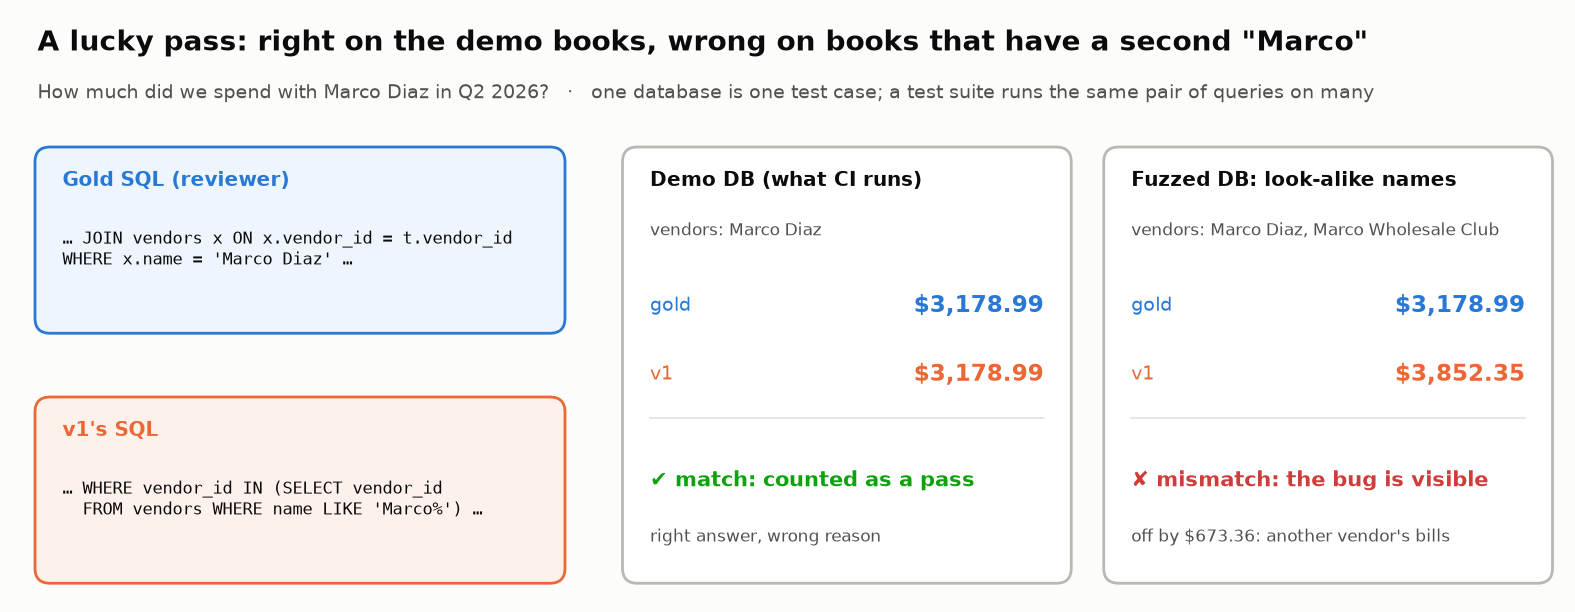

<sub>🖼️ *A lucky pass, caught. The demo DB happens to have one vendor whose name starts with "Marco"; real books can have two.*</sub>

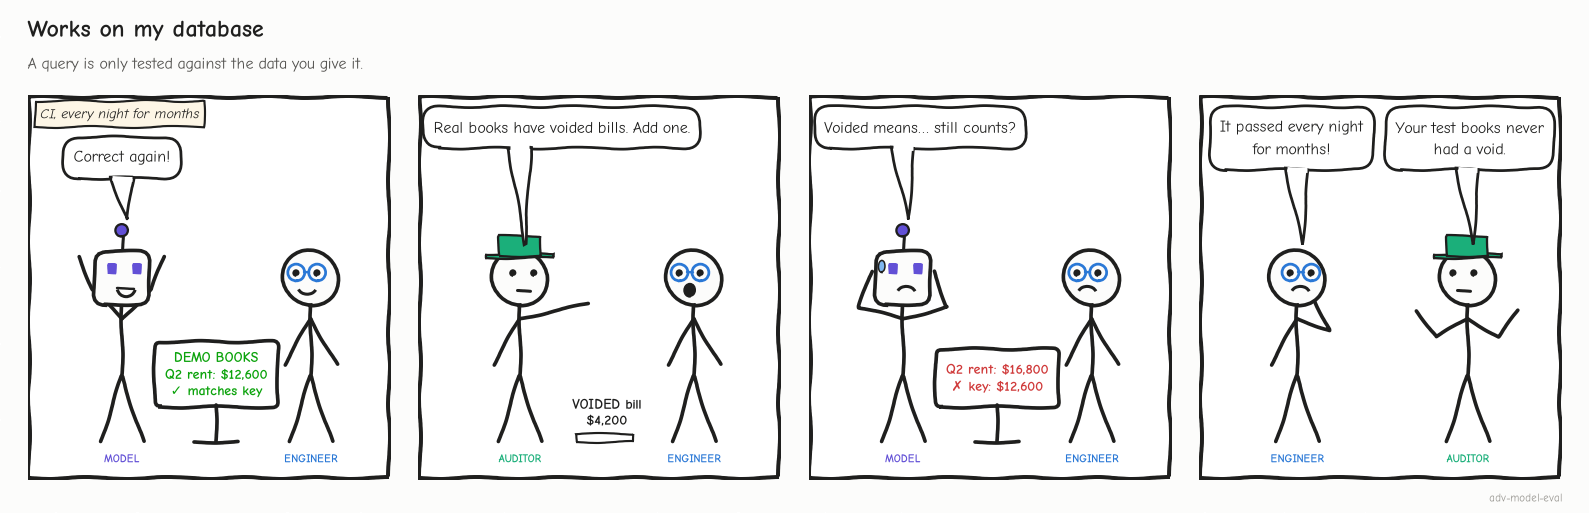

<sub>😄 *If the edge case isn't in your test data, your eval can't see the bug.*</sub>

#### Steps
1. **🧠 Exercise 3A:** write the fuzzer that injects **voided and draft** copies of real transactions. Run the ✅ check: it verifies your fuzzer adds only rows that must *not* count, changes no correct answer, and fools at least one recorded query.
2. 🔮 **Predict:** on the full suite, how many of v1's 40 EX passes survive? How many of v2's 37?
3. Run the suite cell.

<details><summary>💡 Hint 1</summary>

Read the posted rows you want to copy: `con.execute("SELECT txn_date, txn_type, account_id, vendor_id, customer_id, amount FROM transactions WHERE status = 'posted' AND txn_type IN ('bill','expense','invoice','sales_receipt')").fetchall()`. New ids start at `con.execute("SELECT MAX(txn_id) FROM transactions").fetchone()[0] + 1`.
</details>

<details><summary>💡 Hint 2</summary>

For about one row in four (`rng.random() < 0.25`), insert a copy with `status` set to `rng.choice(["void", "draft"])` and a different amount (`round(amount * rng.uniform(0.5, 1.5), 2)`), so a query that wrongly counts it gets a visibly different total. Columns: `(txn_id, txn_date, txn_type, account_id, vendor_id, customer_id, amount, status, doc_number, ref_txn_id, memo)`. Call `con.commit()` at the end.
</details>

<details><summary>✅ Full solution</summary>

```python
def fuzz_void_and_draft(con, rng):
    src = con.execute("SELECT txn_date, txn_type, account_id, vendor_id, customer_id, amount FROM transactions "
                      "WHERE status = 'posted' AND txn_type IN ('bill','expense','invoice','sales_receipt') "
                      "ORDER BY txn_id").fetchall()
    nid = con.execute("SELECT MAX(txn_id) FROM transactions").fetchone()[0] + 1
    rows = []
    for d, typ, acct, vid, cid, amt in src:
        if rng.random() < 0.25:
            rows.append((nid, d, typ, acct, vid, cid, round(amt * rng.uniform(0.5, 1.5), 2),
                         rng.choice(["void", "draft"]), None, None, "entered twice / not approved"))
            nid += 1
    con.executemany("INSERT INTO transactions VALUES (?,?,?,?,?,?,?,?,?,?,?)", rows)
    con.commit()
```
</details>

In [ ]:
# 🧠 YOUR TURN — Exercise 3A: a fuzzer for voided and draft entries
def fuzz_void_and_draft(con, rng):
    """con: a COPY of the books (sqlite3 connection). rng: random.Random. Modify con in place.
    Insert void/draft copies of ~1 in 4 posted bills, expenses, invoices and sales receipts."""
    # TODO 1: read the posted rows to copy (see Hint 1)
    # TODO 2: for ~25% of them, build a new row: new txn_id, same date/type/account/vendor/customer,
    #         a different amount, status 'void' or 'draft'
    # TODO 3: insert the rows and commit
    raise NotImplementedError("Exercise 3A")

In [ ]:
# ✅ CHECK 3A (property checks, not an exact-output match: any fuzzer with these properties is a good one)
FUZZERS["void_and_draft"] = check_fuzzer(fuzz_void_and_draft)

In [ ]:
SUITE = build_suite(FUZZERS)
gold_suite = {q: run_on(SUITE, golden.gold_sql[q]) for q in golden.index}
pred_suite = {m: {q: run_on(SUITE, RECORDED[m][q]) for q in golden.index} for m in MODELS}

def passes_everywhere(m, q, reference):
    return all(results_match(pred_suite[m][q][db], reference[q][db], golden.ordered[q]) for db in SUITE)

layers["Test suite"] = {m: pd.Series({q: passes_everywhere(m, q, gold_suite) for q in golden.index}) for m in MODELS}
ts = layers["Test suite"]
lucky = {m: [q for q in golden.index if ex[m][q] and not ts[m][q]] for m in MODELS}

# which fuzzer exposed each lost pass (a pass can be exposed by several)
expose = pd.DataFrame({m: {db: sum(not results_match(pred_suite[m][q][db], gold_suite[q][db], golden.ordered[q])
                                   for q in lucky[m]) for db in SUITE if db != "demo"} for m in MODELS})
tiles([
    ("Databases in the suite", len(SUITE), "demo + 7 fuzzed + kitchen sink", None),
    ("v1: EX → test suite", f"{pct(ex['v1'].mean())} → {pct(ts['v1'].mean())}", f"{len(lucky['v1'])} passes lost", "warning"),
    ("v2: EX → test suite", f"{pct(ex['v2'].mean())} → {pct(ts['v2'].mean())}", f"{len(lucky['v2'])} passes lost", "warning"),
    ("Gap (v2 − v1)", f"{signed(100 * (ts['v2'].mean() - ts['v1'].mean()))} pts", "it got wider", "critical"),
])
fig, ax = plt.subplots(figsize=(8.5, 3.4))
order = expose.sum(axis=1).sort_values().index
for i, m in enumerate(MODELS):
    ax.barh([y + (0.2 if i else -0.2) for y in range(len(order))], expose.loc[order, m], height=0.38,
            color=PALETTE[i * 6], label=m)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("demo-DB passes this database exposed as mismatches")
ax.set_axisbelow(True)
silent = [db for db in expose.index if expose.loc[db].sum() == 0]
ax.set_title(f"The kitchen sink exposes {expose.loc['kitchen_sink'].sum()} of {sum(len(v) for v in lucky.values())} lost passes; "
             f"{len(silent)} fuzzers expose none")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

ex_q = "G08"
print(f"{ex_q}: {golden.question[ex_q]}")
v1_sql = RECORDED["v1"][ex_q]
start = v1_sql.index("(SELECT")
print(f"  v1 picks the vendor with: {v1_sql[start:v1_sql.index(')', start) + 1]}")
for db in ("demo", "sibling_vendors"):
    print(f"  {db:>16}: gold {gold_suite[ex_q][db]}   v1 {pred_suite['v1'][ex_q][db]}")
insight(
    f"The suite removed {len(lucky['v1'])} of v1's passes and {len(lucky['v2'])} of v2's, and the gap widened to "
    f"{signed(100 * (ts['v2'].mean() - ts['v1'].mean()))} points",
    f"{ex_q} is a textbook lucky pass: v1 matched vendors with `LIKE 'Marco%'`, which is right only while the books hold one "
    "vendor whose name starts with \"Marco\". The test suite is stricter in **both** directions, though: it fails a "
    "prediction whenever it disagrees with the gold on *any* database. If the gold itself is wrong on an edge case, "
    "a correct model now fails. Rule of thumb: **a test suite removes lucky passes, and it makes a wrong answer key "
    "louder, not quieter.**",
    kind="surprise",
)
insight(
    "Single-database execution accuracy has false positives; a distilled suite of databases removes most of them (Zhong et al., 2020)",
    "Zhong, Yu & Klein (EMNLP 2020) generated many random databases per question and distilled a small suite chosen to "
    "tell the gold query apart from slightly altered versions of it. Test-suite accuracy approximates **semantic** accuracy (does the query mean "
    "the same thing as the gold?), but it remains an upper bound: a query can still pass every database in the suite and be wrong.",
    kind="research",
)

#### Checkpoint
Your ✅ (or the 📝 fallback), four tiles, a bar chart by fuzzer, a printed example, and two cards.

#### Expected Output (with the reference fuzzer)
```
G08: How much did we spend with Marco Diaz in Q2 2026?
  v1 picks the vendor with: (SELECT vendor_id FROM vendors WHERE name LIKE 'Marco%')
              demo: gold [(3178.99,)]   v1 [(3178.99,)]
   sibling_vendors: gold [(3178.99,)]   v1 [(3852.35,)]
```
Tiles: **9** databases; v1 **80% → 68%** (6 passes lost); v2 **74% → 60%** (7 lost); gap **−8 pts**. Chart title: *"The kitchen sink exposes 13 of 13 lost passes; 2 fuzzers expose none"*.
🤯 card: *"The suite removed 6 of v1's passes and 7 of v2's, and the gap widened to −8 points"*.

If you wrote your own fuzzer, your counts may differ slightly; the direction holds.

> 🔍 **Look at the two silent fuzzers.** `jitter` finds nothing because no query here depends on a coincidence of amounts. `no_vendor` finds nothing for a stranger reason: the one query it should catch has a gold that makes the same mistake. Task 4 is about that.

**Bridge:** the suite failed both models more often, but it compares against the gold. Who checks the gold?

### Task 4: Audit the Answer Key (the plot twist)

#### Goal
Check the **gold** answers against an independent source of truth, then re-score both models against the truth.

> 📐 **Key idea: the answer key is data, and data has bugs.** A gold query is written by someone (or something) and can be wrong. To audit it you need a source of truth that doesn't share its mistakes. Here it is the **report engine**: the product's existing vendor, account and receivables reports, which accountants already reconcile against bank statements. `report_engine(qid, db)` returns the trusted number for a golden question on any database.
>
> Where a model and the gold disagree, there are three possibilities: the model is wrong, the gold is wrong, or both are. Only the truth tells them apart.

#### Steps
1. 🔮 **Predict:** v1 lost 6 passes and v2 lost 7 in Task 3. How many of those 13 do you think were **the gold's** fault?
2. Run the audit cell. Read the table of wrong golds: what's wrong with each, who wrote it, and whether each model reproduces it.
3. Run the re-scoring cell.

In [ ]:
truth_suite = {q: {db: report_engine(q, con) for db, con in SUITE.items()} for q in golden.index}
gold_ok = pd.Series({q: all(results_match(gold_suite[q][db], truth_suite[q][db], golden.ordered[q]) for db in SUITE)
                     for q in golden.index})
agrees_with_gold = {m: pd.Series({q: passes_everywhere(m, q, gold_suite) for q in golden.index}) for m in MODELS}
bad = gold_ok[~gold_ok].index
audit = pd.DataFrame({
    "question": golden.question[bad].str[:52],
    "what's wrong with the gold": [auditor_note(q) for q in bad],
    "gold written by": golden.gold_written_by[bad],
    "v1 agrees with it": agrees_with_gold["v1"][bad].map({True: "✔ everywhere", False: "—"}),
    "v2 agrees with it": agrees_with_gold["v2"][bad].map({True: "✔ everywhere", False: "—"}),
})
display(audit)
by_author = golden.assign(wrong=~gold_ok).groupby("gold_written_by")["wrong"].agg(["sum", "count"])
print(by_author.rename(columns={"sum": "wrong golds", "count": "golds written"}))

In [ ]:
layers["Audited (vs truth)"] = {m: pd.Series({q: passes_everywhere(m, q, truth_suite) for q in golden.index}) for m in MODELS}
aud = layers["Audited (vs truth)"]
n_bad, n_bad_v1 = len(bad), int((golden.gold_written_by[bad] == "v1 draft").sum())
tiles([
    ("Wrong golds", f"{n_bad} of {len(golden)}", f"{n_bad_v1} were v1's approved drafts", "critical"),
    ("v1 reproduces the wrong gold", f"{agrees_with_gold['v1'][bad].sum()} of {n_bad}", "same SQL, same mistake", "critical"),
    ("v2 reproduces the wrong gold", f"{agrees_with_gold['v2'][bad].sum()} of {n_bad}", "it disagrees with every one", "good"),
    ("Audited: v1 → v2", f"{pct(aud['v1'].mean())} → {pct(aud['v2'].mean())}",
     f"{signed(100 * (aud['v2'].mean() - aud['v1'].mean()))} pts", "good"),
])

fig, ax = plt.subplots(figsize=(8.5, 2.6))
rates = (by_author["sum"] / by_author["count"]).sort_values()
ax.barh(rates.index, 100 * rates, color=[PALETTE[0] if i == "reviewer" else PALETTE[1] for i in rates.index], height=0.5)
for y, (who, r) in enumerate(rates.items()):
    ax.text(100 * r + 0.8, y, f"{100 * r:.0f}%  ({by_author.loc[who, 'sum']} of {by_author.loc[who, 'count']})",
            va="center", fontsize=10, color="#52514e")
ax.set_xlim(0, 40)
ax.set_xlabel("share of golds that are wrong")
ax.set_title(f"Approved v1 drafts are wrong {rates['v1 draft'] / rates['reviewer']:.1f}× as often as hand-written golds")
ax.grid(axis="y", visible=False)
plt.show()

insight(
    f"The answer key was v1's homework: v1 'agrees' with {agrees_with_gold['v1'][bad].sum()} of the {n_bad} wrong golds "
    f"because it wrote them. Against the truth, v2 beats v1 {pct(aud['v2'].mean())} to {pct(aud['v1'].mean())}",
    f"Every v1 bug the reviewer couldn't see (voided entries counted, credits added, a vendor-name `LIKE`) went into the key, "
    f"so CI rewarded v1 for repeating its own mistakes and failed v2 for getting them right. This isn't noise that averages "
    f"out; the gold's errors are **correlated with the incumbent**, which biases every comparison toward it. The same "
    f"happens whenever a golden set is bootstrapped from the current model's outputs, a common shortcut. "
    "Rule of thumb: **never let the model you're evaluating write the answer key, and audit any gold the incumbent drafted "
    "against an independent source before a migration.**",
    kind="surprise",
)
insight(
    "Over half of a popular text-to-SQL benchmark's dev examples have annotation errors, and fixing them reshuffles the leaderboard (Jin et al., 2026)",
    "Jin, Choi, Zhu & Kang (arXiv 2601.08778, Jan 2026) report annotation errors in **52.8%** of BIRD Mini-Dev and **62.8%** "
    "of the Spider 2.0-Snow examples they audited. Re-scoring 16 agents on a corrected BIRD sample moved them by −7% to +31% "
    "(relative) and up to **9 ranks**. If public benchmarks look like this, an internal golden set nobody has audited probably does too.",
    kind="research",
)

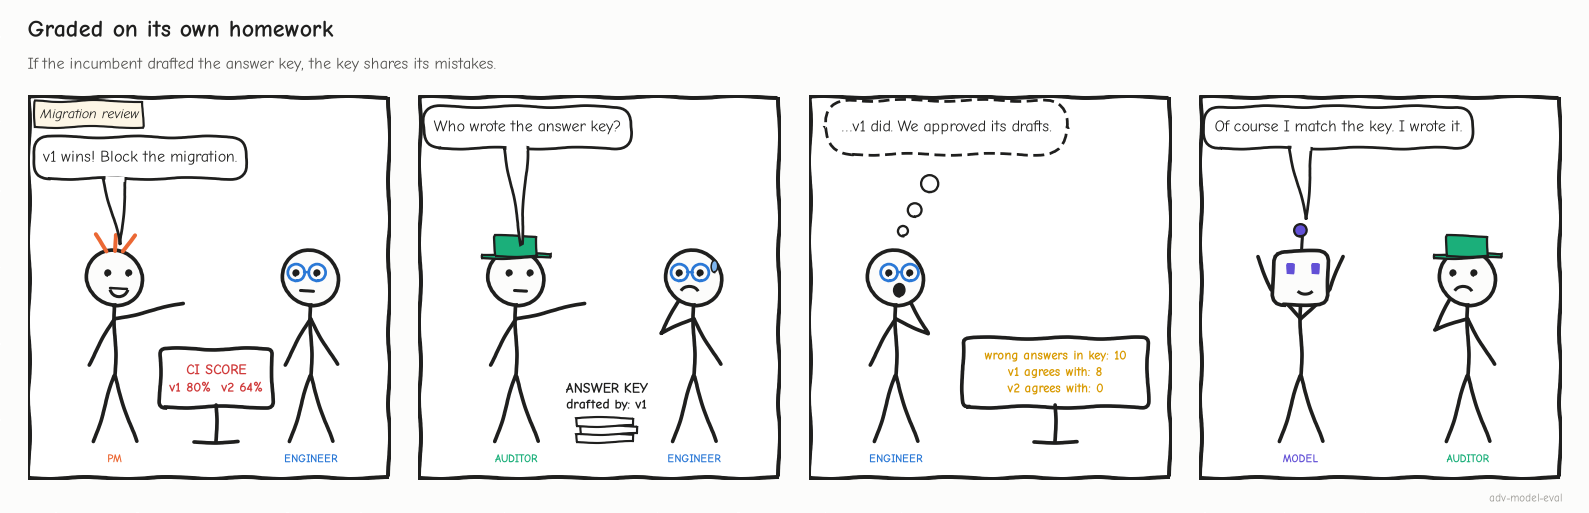

<sub>😄 *When the incumbent drafted the answer key, it agrees with the key's mistakes.*</sub>

#### Checkpoint
A 10-row audit table, a by-author count, four tiles, a bar chart and two cards.

#### Expected Output
```
                 wrong golds  golds written
gold_written_by
reviewer                   2             20
v1 draft                   8             30
```
The two reviewer-written errors are both *"'last month' = month − 1, so January asks for month 0"* (BookSQL's own example query for "last month" uses that pattern). Tiles: **10 of 50** wrong golds (8 from v1 drafts); v1 reproduces **8 of 10**; v2 **0 of 10**; audited **56% → 80%** (**+24 pts**).
🤯 card: *"The answer key was v1's homework: v1 'agrees' with 8 of the 10 wrong golds because it wrote them. Against the truth, v2 beats v1 80% to 56%"*.

**Bridge:** with the key fixed, every golden question has exactly one right answer. Real owners don't ask questions like that.

### Task 5: Questions With More Than One Right Answer

#### Goal
Score 10 real-world **ambiguous** questions three ways and find the scoring rule that rewards the behavior owners need.

> 📐 **Key idea: a question can have several valid readings.** *"How much did we spend on contractors last quarter?"* Does "contractors" mean the vendors you file **1099-NEC** forms for (self-employed people, in any expense account), or the **Contract Labor** account (which includes a staffing agency, a corporation that gets no 1099)? Without house rules, "spend" could also be **accrual** (when the bill arrived) or **cash** (when you paid), and "last quarter" could be the **calendar** or **fiscal** quarter. Harbor & Pine's metric glossary settles basis and quarters; it never defined "contractors".
>
> Three ways to grade an answer to an ambiguous question:
>
> | Rule | Pass if… | Problem |
> |---|---|---|
> | **Single gold** | the number matches the one reading the reviewer picked | Grades which reading the model *guessed* |
> | **Reading set** | the number matches *any* acceptable reading | Can't see whether the owner knows which reading they got |
> | **Reading set + states it** | acceptable **and** the answer says which reading it used (or asks) | Rewards what owners need |

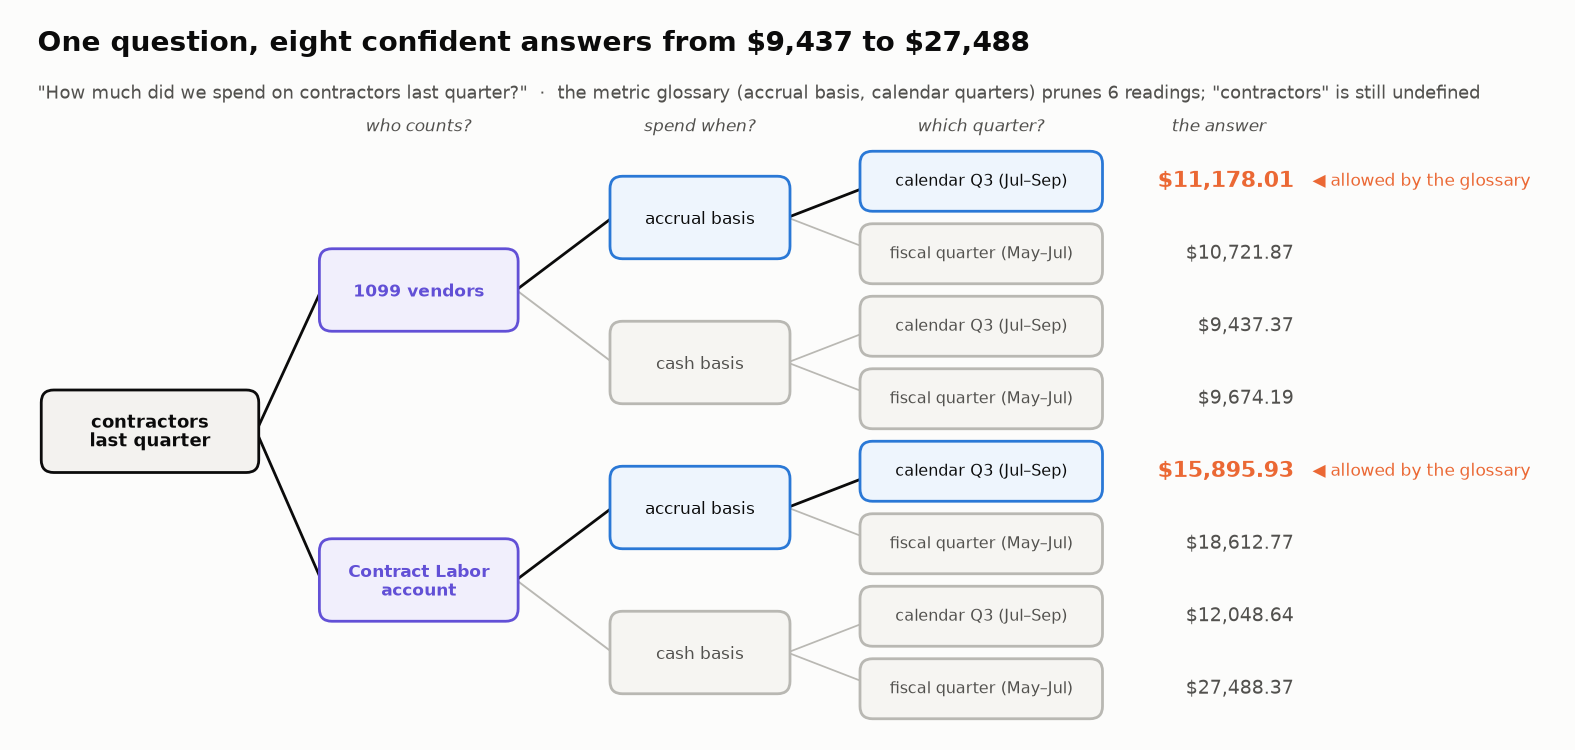

<sub>🖼️ *Every leaf is a number Ledgerly Ask could print with total confidence. Each split is a word the owner didn't define.*</sub>

#### Steps
1. 🔮 **Predict:** how many of the 10 answers from each model state which reading they used?
2. Run the cell. Read a few answers side by side, then the scoring table.

In [ ]:
rows = []
for aid, (question, readings) in AMBIGUOUS.items():
    values = [run_sql(DEMO, sql)[0][0] for _, sql in readings]
    row = {"id": aid, "question": question, "readings": len(readings),
           "spread": max(values) / min(values) if min(values) else float("nan")}
    for m in MODELS:
        ans = ambiguous_answer(m, aid, DEMO)
        v = ans["value"]
        row[f"{m} answer"] = ans["text"]
        row[f"{m} single gold"] = v is not None and abs(v - values[0]) <= 0.01
        row[f"{m} reading set"] = v is None or any(abs(v - x) <= 0.01 for x in values)   # a clarifying question is acceptable
        row[f"{m} states it"] = ans["states_assumption"]
    rows.append(row)
amb = pd.DataFrame(rows).set_index("id")
with pd.option_context("display.max_colwidth", 70):
    display(amb[["question", "v1 answer", "v2 answer"]].head(5))

amb_scores = pd.DataFrame({
    "single gold": [amb[f"{m} single gold"].sum() for m in MODELS],
    "reading set": [amb[f"{m} reading set"].sum() for m in MODELS],
    "states its reading": [amb[f"{m} states it"].sum() for m in MODELS],
    "reading set + states it": [(amb[f"{m} reading set"] & amb[f"{m} states it"]).sum() for m in MODELS],
}, index=MODELS)
display(amb_scores.rename(columns=lambda c: f"{c} (of {len(amb)})"))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
s = amb["spread"].sort_values()
ax.barh([f"{i}  " + (amb.question[i] if len(amb.question[i]) <= 44 else amb.question[i][:42] + "…") for i in s.index], s.values, color=[PALETTE[1] if v >= 1.25 else "#b9b8b3" for v in s.values], height=0.6)
for y, v in enumerate(s.values):
    ax.text(v + 0.03, y, f"{v:.2f}×", va="center", fontsize=9, color="#52514e")
ax.axvline(1, color="#0b0b0b", lw=1)
ax.set_xlabel("largest reading ÷ smallest reading (1.00× = the readings happen to agree)")
ax.set_title(f"Readings of the same question differ by up to {s.max():.1f}×")
ax.grid(axis="y", visible=False)
plt.show()

big = int((amb["spread"] >= 1.25).sum())
silent = {m: int((~amb[f"{m} states it"]).sum()) for m in MODELS}
insight(
    f"Single-gold scoring ranks v2 {amb_scores.loc['v2', 'single gold']}/10 vs v1 {amb_scores.loc['v1', 'single gold']}/10. "
    f"That's a coin toss over readings: both models gave an acceptable reading every time",
    f"On {big} of 10 questions the readings differ by 25% or more (up to {s.max():.1f}×), so the reading matters more than the SQL. "
    f"The real difference is **silence**: v1 picks a reading without saying so on {silent['v1']} of 10 answers, v2 on "
    f"{silent['v2']}. An owner who reads v1's silent \"{amb.loc['A01', 'v1 answer']}\" for contractors can't tell it includes "
    "a staffing agency (a corporation, no 1099) and leaves out the plumber and the designer, who do get 1099s. "
    "Rule of thumb: **grade ambiguous questions against a set of readings, require the answer to state its reading "
    "(or ask), and shrink the ambiguity upstream by adding the term to the metric glossary.**",
)
insight(
    "Ambiguity, not SQL skill, explains much of the failure on ambiguous questions (AMBROSIA, NeurIPS 2024; ROSE, ACL 2026)",
    "AMBROSIA (Saparina & Lapata, NeurIPS 2024) built databases where questions have several valid SQL readings and found that "
    "even strong models struggle to notice the ambiguity; ROSE (Pei et al., ACL 2026) cites it for the finding that more than "
    "half of failures there arise from ambiguity, and argues execution accuracy against a single gold can't credit a different valid reading. "
    "Snowflake's 2024 write-up of Cortex Analyst's evaluation took the practical route: human reviewers accepted *several* gold queries per question.",
    kind="research",
)

#### Checkpoint
Five sample answers side by side, a 2-row scoring table, a bar chart of spreads, and two cards.

#### Expected Output

| | single gold | reading set | states its reading | reading set + states it |
|---|---|---|---|---|
| v1 | 5 | 10 | 1 | 1 |
| v2 | 6 | 10 | 5 | 5 |

Chart title: *"Readings of the same question differ by up to 4.0×"*. 💡 card: *"Single-gold scoring ranks v2 6/10 vs v1 5/10. That's a coin toss over readings: both models gave an acceptable reading every time"*.

> 🏭 **In production:** two questions (A07 repairs, A10 Lighthouse Inn) are ambiguous in words but not in numbers: every reading gives the same total on these books. Measure the **spread** before you spend effort disambiguating.

**Bridge:** the golden set is 50 questions. Production is thousands a day with no gold at all. Can you still catch wrong SQL there?

### Task 6: No Gold? Check Consistency Instead

#### Goal
Catch wrong answers in production **without** any answer key, using a relation the answers must satisfy, then find what that check can't see.

> 📐 **Key idea: metamorphic testing.** You may not know the right answer to *"what did we spend on Packaging in Q2?"*, but you know it must equal April + May + June. A **metamorphic relation** is a rule connecting several answers. Ask the related questions, check the rule, and a violation proves at least one answer is wrong. It needs no gold and runs on live traffic.
>
> What it can't see: a model that makes the **same** mistake in every related answer satisfies the relation perfectly. Consistent isn't correct.

#### Steps
1. **🧠 Exercise 6A:** complete `decomposition_gap`. Run the ✅ check.
2. 🔮 **Predict:** v2 answers 24 families of 4 questions (a quarter and its 3 months) on a real customer's messier books. About 1 answer in 9 is wrong. What share of the wrong answers will the relation catch?
3. Run the production cell, then the blind-spot cell.

<details><summary>💡 Hint</summary>

Pull the single number out of each result with a helper: an error string, an empty list, or `None` means "no number". If any of the four numbers is missing, return `float("inf")` (a broken answer is a violation). Otherwise return `abs(q - sum(months))`, or `0.0` when that is within `tol`.
</details>

<details><summary>✅ Full solution</summary>

```python
def decomposition_gap(quarter_rows, month_rows_list, tol=0.01):
    def val(rows):
        if isinstance(rows, str) or not rows or rows[0][0] is None:
            return None
        return float(rows[0][0])
    q, ms = val(quarter_rows), [val(r) for r in month_rows_list]
    if q is None or any(m is None for m in ms):
        return float("inf")
    gap = abs(q - sum(ms))
    return 0.0 if gap <= tol else gap
```
</details>

In [ ]:
# 🧠 YOUR TURN — Exercise 6A: the quarter must equal the sum of its months
def decomposition_gap(quarter_rows, month_rows_list, tol=0.01):
    """quarter_rows: result of the quarter question, e.g. [(1234.5,)]; month_rows_list: three month results.
    Return the violation in dollars: 0.0 if |quarter − sum(months)| <= tol; float('inf') if any answer is
    an error, empty, or None; otherwise the absolute gap."""
    # TODO 1: a helper that extracts the number from a result (or None for error / empty / NULL)
    # TODO 2: any missing number → float("inf")
    # TODO 3: gap = abs(quarter − sum(months)); return 0.0 if gap <= tol else gap
    raise NotImplementedError("Exercise 6A")

In [ ]:
# ✅ CHECK 6A
decomposition_gap = use_or_fallback("6A", decomposition_gap, _reference_decomposition_gap, cases=[
    ([(300.0,)], [[(100.0,)], [(100.0,)], [(100.0,)]]),          # holds
    ([(300.0,)], [[(100.0,)], [(100.0,)], [(99.995,)]]),         # within a cent
    ([(300.0,)], [[(100.0,)], [(80.0,)], [(100.0,)]]),           # $20 violation
    ([(300.0,)], [[(100.0,)], "ERROR: no such table", [(100.0,)]]),  # broken answer
    ([(None,)], [[(1.0,)], [(1.0,)], [(1.0,)]]),                  # NULL total
])

In [ ]:
prod_books = make_production_books()

def run_families(sql_for):
    out = []
    for f in production_families():
        qs = [("account_spend", (f["account"], f["quarter"]))] + [("account_spend", (f["account"], mm)) for mm in f["months"]]
        res = [run_sql(prod_books, sql_for(t, a)) for t, a in qs]
        wrong = [not results_match(r, run_sql(prod_books, write_sql(t, a))) for r, (t, a) in zip(res, qs)]  # truth: only a simulation can see this
        out.append({"family": f"{f['account']} {f['quarter']}", "gap $": decomposition_gap(res[0], res[1:]),
                    "wrong answers": sum(wrong)})
    return pd.DataFrame(out).set_index("family")

fam = run_families(lambda t, a: v2_sql_for(t, a)[0])
flagged = fam["gap $"] > 0
n_wrong = int(fam["wrong answers"].sum())
caught = int(fam.loc[flagged, "wrong answers"].sum())
tiles([
    ("Production questions answered", 4 * len(fam), f"{len(fam)} families of 4", None),
    ("Wrong answers (truth)", n_wrong, f"{pct(n_wrong / (4 * len(fam)))} of answers; unknown in real life", "serious"),
    ("Families flagged", f"{flagged.sum()} of {len(fam)}", "no gold needed", "warning"),
    ("Wrong answers inside flagged families", f"{caught} of {n_wrong}", "found with zero labels", "good"),
])
display(fam[flagged].round(2))

In [ ]:
# 🔎 The blind spot: the same model, but with ONE systematic habit (it always adds vendor credits instead of subtracting)
fam_sys = run_families(lambda t, a: write_sql(t, a, "CREDIT", "v2"))
sys_wrong, sys_flagged = int(fam_sys["wrong answers"].sum()), int((fam_sys["gap $"] > 0).sum())
print(f"Systematic bug: {sys_wrong} of {4 * len(fam_sys)} answers wrong, {sys_flagged} of {len(fam_sys)} families flagged.")
insight(
    f"Consistency checks caught all {caught} of v2's {n_wrong} wrong production answers without a single gold, "
    f"and caught 0 of {sys_wrong} when the same bug appeared everywhere",
    f"v2's slips are **sporadic**: one month query drops the last day, another counts a voided entry, so the parts stop "
    f"adding up and {flagged.sum()} families light up. A **systematic** bug moves the quarter and its months together and the "
    "relation holds perfectly. That's the division of labor: metamorphic checks watch production for sporadic errors, "
    "fuzzed test suites catch systematic ones before release. Rule of thumb: **run cheap relations on live traffic "
    "(parts sum to the whole, paraphrases agree), and never read 'consistent' as 'correct'.**",
    kind="production",
)

#### Checkpoint
Your ✅ (or 📝), four tiles, a table of flagged families, one printed line about the systematic bug, and a card.

#### Expected Output
Tiles: **96** questions; **11** wrong (11%); **8 of 24** families flagged; **11 of 11** wrong answers inside flagged families.
```
Systematic bug: 96 of 96 answers wrong, 0 of 24 families flagged.
```
🏭 card: *"Consistency checks caught all 11 of v2's 11 wrong production answers without a single gold, and caught 0 of 96 when the same bug appeared everywhere"*.

**Bridge:** you now have five scores per model, an ambiguity profile, and a production monitor. Time to decide.

### Task 7: The Migration Decision

#### Goal
Put every layer on one chart, test the v1-vs-v2 difference properly, and render the verdict.

> 📐 **Key idea: compare models on the same questions (Lab 05b).** Both models answered the same 50 questions, so compare them **question by question**. Only **discordant pairs** carry information: questions v2 got right and v1 wrong ("fixed"), and the reverse ("broke"). The exact **McNemar test** asks how surprising the split is if the models were equally good (each changed question a fair coin flip). A **Wilson interval** puts an error bar on each pass rate; on 50 questions expect roughly ±11 points.

#### Steps
1. 🔮 **Predict:** on the audited scores, how many questions did v2 fix and how many did it break?
2. Run the cell: the score ladder, the paired test, v2's remaining failures, and the verdict.
3. Write your recommendation to the PM in the ✍️ cell.

In [ ]:
LADDER = ["Exact match", "CI (strict EX)", "EX (one DB)", "Test suite", "Audited (vs truth)"]
ladder = pd.DataFrame({L: {m: 100 * layers[L][m].mean() for m in MODELS} for L in LADDER}).T

fig, ax = plt.subplots(figsize=(9, 3.8))
x = range(len(LADDER))
for i, m in enumerate(MODELS):
    ax.plot(x, ladder[m], marker="o", color=PALETTE[i * 6], label=m)
    for xi, v in zip(x, ladder[m]):
        other = ladder.loc[LADDER[xi], MODELS[1 - i]]
        above = v >= other or v < 12
        off, ha = ((0, 10), "center") if above and v >= 12 else ((12, -4), "left")
        ax.annotate(f"{v:.0f}%", (xi, v), xytext=off, textcoords="offset points", ha=ha, fontsize=9.5,
                    color=PALETTE[i * 6], weight="bold")
ax.set_xticks(list(x), [L.replace(" (", "\n(") for L in LADDER])
ax.set_ylim(0, 100)
ax.set_ylabel("pass rate on the 50 golden questions")
ax.set_title("The same SQL, five grades: v2 trails at every layer until the answer key is fixed")
ax.legend(loc="lower right")
plt.show()

fixed = int((aud["v2"] & ~aud["v1"]).sum())
broke = int((aud["v1"] & ~aud["v2"]).sum())
p_mc = mcnemar_exact_p(fixed, broke)
ci_v = {m: wilson_ci(int(aud[m].sum()), len(golden)) for m in MODELS}
v2_fail = [q for q in golden.index if not aud["v2"][q]]
display(pd.DataFrame({"question": golden.question[v2_fail].str[:55], "what v2 got wrong": [auditor_note(q, "v2") for q in v2_fail]}))
tiles([
    ("v2 fixed", fixed, "v1 wrong → v2 right", "good"),
    ("v2 broke", broke, "v1 right → v2 wrong", "warning"),
    ("McNemar p", f"{p_mc:.3f}", "< 0.05: unlikely to be chance", "good" if p_mc < 0.05 else "warning"),
    ("v2 audited (95% CI)", pct(aud["v2"].mean()), f"{pct(ci_v['v2'][0])}–{pct(ci_v['v2'][1])}", None),
])

In [ ]:
GATE = -0.02                       # CI's rule: block if v2 is more than 2 points worse than v1
v2_better = aud["v2"].mean() > aud["v1"].mean() and p_mc < 0.05
disclosure = amb_scores.loc["v2", "states its reading"] / len(amb)
monitor_ok = caught == n_wrong

if v2_better and disclosure >= 0.8:
    decision = "SHIP"
elif v2_better:
    decision = "SHIP WITH CAUTION"
else:
    decision = "BLOCK"

reasons = [
    f"**v2 is better, not worse:** {pct(aud['v2'].mean())} vs {pct(aud['v1'].mean())} against the audited truth "
    f"(v2 fixed {fixed}, broke {broke}; McNemar p = {p_mc:.3f}). CI's {signed(100 * gap_ci)} pts came from text style, "
    f"float noise, and an answer key v1 drafted.",
    f"**Fix the eval before the next gate:** correct the {n_bad} wrong golds, switch CI to `results_match` on the "
    f"{len(SUITE)}-database suite, and stop seeding golds from the model under test.",
    f"**Ship with guards for v2's known slips** ({len(v2_fail)} audited failures: "
    + ", ".join(f"{n}× {note}" for note, n in pd.Series([auditor_note(q, "v2") for q in v2_fail]).value_counts().items())
    + "): add a SQL lint that flags spend queries without `status = 'posted'` or with `bill_payment`/`payment` in the type list.",
    f"**Before GA, make v2 state its reading:** it does so on {amb_scores.loc['v2', 'states its reading']} of {len(amb)} "
    "ambiguous questions; add 'contractors', 'this year' and 'pay' to the metric glossary.",
    f"**Watch production:** the metamorphic monitor caught {caught} of {n_wrong} sporadic errors offline; run it on live traffic.",
]
verdict(decision, reasons)

#### Checkpoint
A five-layer chart, a table of v2's audited failures, four tiles, and a ⚠️ verdict banner with five reasons.

#### Expected Output
Chart title: *"The same SQL, five grades: v2 trails at every layer until the answer key is fixed"* (v1 68 → 80 → 80 → 68 → 56; v2 6 → 64 → 74 → 60 → 80).
Tiles: v2 fixed **16**, broke **4**, McNemar p **0.012**, v2 audited **80%** (95% CI 67%–89%).
Banner: ⚠️ **SHIP WITH CAUTION**, first reason *"v2 is better, not worse: 80% vs 56% against the audited truth (v2 fixed 16, broke 4; McNemar p = 0.012)…"*.

#### ✍️ Your call

**What I'd tell the PM (two sentences, kind and specific):**

> e.g. "Migrate: v2 gives owners the right number 80% of the time vs 56% for v1; CI said the opposite because the answer key was v1's own drafts. Ship with two guards and a disclosure fix, and we'll have the eval fixed before the January cutover."

**The one chart I'd put in the launch doc, and why:**

---

## 🔌 Optional: Let a Real Model Write the SQL

Everything above used recorded SQL. This cell asks a real model to write SQL for a few golden questions from the schema and the metric glossary, then grades each query with your comparator on the audited suite. It runs offline by default (`PROVIDER = "mock"` returns v2's recorded SQL).

| `PROVIDER` | Who writes the SQL | Needs |
|---|---|---|
| `"mock"` *(default)* | v2's recorded SQL | nothing |
| `"openai"` | `OPENAI_MODEL` via the Responses API (`client.responses.parse`) | `OPENAI_API_KEY` in Colab 🔑 Secrets or env, `pip install openai` |
| `"anthropic"` | `ANTHROPIC_MODEL` via `client.messages.parse` | `ANTHROPIC_API_KEY`, `pip install anthropic` |

No `temperature` is sent: current Anthropic models reject sampling parameters, and temperature 0 wouldn't make SQL generation reproducible anyway. The structured output has an `assumptions` field, so Task 5's "states its reading" check works on real answers too.

In [ ]:
# ⚙️ CONFIG — model IDs live only in this cell
PROVIDER = "mock"                      # "mock" | "openai" | "anthropic"
OPENAI_MODEL = "gpt-6-luna"
ANTHROPIC_MODEL = "claude-haiku-5-5"

import os

from pydantic import BaseModel, Field


class SQLAnswer(BaseModel):
    assumptions: str = Field(description="Any reading you chose for an ambiguous term, in one sentence; empty if none")
    sql: str = Field(description="One SQLite SELECT statement that answers the question")


SYSTEM = (f"You write SQLite for a small business's books. Schema:\n{SCHEMA_DOC}\n\n{GLOSSARY}\n"
          "Today's date is in company.as_of. Return one SELECT statement.")


def _get_secret(name):
    try:
        from google.colab import userdata  # type: ignore
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)


def generate_sql(qid):
    question = golden.question[qid]
    if PROVIDER == "openai":
        from openai import OpenAI
        resp = OpenAI(api_key=_get_secret("OPENAI_API_KEY")).responses.parse(
            model=OPENAI_MODEL, instructions=SYSTEM, input=question, text_format=SQLAnswer)
        return resp.output_parsed
    if PROVIDER == "anthropic":
        import anthropic
        resp = anthropic.Anthropic(api_key=_get_secret("ANTHROPIC_API_KEY")).messages.parse(
            model=ANTHROPIC_MODEL, max_tokens=1024, system=SYSTEM,
            messages=[{"role": "user", "content": question}], output_format=SQLAnswer)
        return resp.parsed_output
    return SQLAnswer(assumptions="", sql=RECORDED["v2"][qid])


if PROVIDER != "mock" and not _get_secret(f"{PROVIDER.upper()}_API_KEY"):
    print(f"⚠️  No {PROVIDER.upper()}_API_KEY found. Falling back to PROVIDER = 'mock'.")
    PROVIDER = "mock"

for qid in ["G08", "G23", "G33", "G35", "G38"]:
    ans = generate_sql(qid)
    ok = all(results_match(run_sql(con, ans.sql), truth_suite[qid][db], golden.ordered[qid]) for db, con in SUITE.items())
    print(f"{qid} {'✅' if ok else '❌'}  {golden.question[qid][:58]:<58}" + (f"  [{ans.assumptions}]" if ans.assumptions else ""))
print(f"\nSQL written by: {PROVIDER}" + ("" if PROVIDER == "mock" else f" ({OPENAI_MODEL if PROVIDER == 'openai' else ANTHROPIC_MODEL})"))

#### Expected Output (mock)
```
G08 ✅  How much did we spend with Marco Diaz in Q2 2026?
G23 ✅  How much did we spend with Mercato Market in June 2026?
G33 ✅  How much did we spend with Rivera Plumbing in Q3 2026?
G35 ✅  What did we spend on Meals last month?
G38 ✅  How much revenue did Driftwood Cafe bring in during February 2026?

SQL written by: mock
```
These five are questions where the CI answer key was wrong or v1 passed by luck. With a real model, any ❌ is worth reading: run the query on `SUITE["demo"]` and on the database that breaks it.

---

## Validation or Success Criteria

You've completed the lab if you can explain or demonstrate each of these:

- [ ] Why exact match on SQL text measures style, and why v1's unusually high exact-match rate was a clue.
- [ ] What your comparator treats as the same answer (cents, column order, row order unless ranked, errors) and why an over-lenient one inflates scores.
- [ ] What a lucky pass is, and how a suite of fuzzed databases removes it.
- [ ] Why a stricter metric against a wrong answer key makes the key's errors louder.
- [ ] How to audit gold answers against an independent source, and why gold errors **correlated with the incumbent** bias a migration decision.
- [ ] How to grade ambiguous questions (reading set + states its reading) and when ambiguity doesn't matter (spread ≈ 1×).
- [ ] What a metamorphic relation catches without gold, and the kind of bug it can't see.
- [ ] How the paired McNemar test and Wilson intervals support the migration verdict.

Run the self-test. It should print `✅ All checks passed`.

In [ ]:
# SELF-TEST: the lab's key invariants
assert (ci["v1"].sum(), ci["v2"].sum()) == (40, 32), "CI scores"
assert (em["v1"].sum(), em["v2"].sum()) == (34, 3), "exact match"
assert (ex["v1"].sum(), ex["v2"].sum()) == (40, 37), "comparator"
assert ts["v1"].sum() < ex["v1"].sum() and ts["v2"].sum() < ex["v2"].sum(), "the suite removes passes"
assert (n_bad, n_bad_v1) == (10, 8) and agrees_with_gold["v1"][bad].sum() == 8, "gold audit"
assert (aud["v1"].sum(), aud["v2"].sum()) == (28, 40), "audited scores"
assert (fixed, broke) == (16, 4) and p_mc < 0.05, "paired test"
assert caught == n_wrong and sys_flagged == 0, "metamorphic checks"
assert decision == "SHIP WITH CAUTION"
print("✅ All checks passed")

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `NameError: name 'golden' is not defined` (or `insight`, `run_sql`) | A setup cell wasn't run | Run the three setup cells, or *Runtime → Run all* |
| `NameError` for `ex`, `SUITE`, `truth_suite`, `amb_scores` … | Tasks build on each other | Re-run the earlier task's cells in order |
| `❌ Exercise 2A: … test case 2` | Column order not handled | Try every permutation of the prediction's columns (Hint 2) |
| `❌ Exercise 2A: … test case 4` | Row order ignored even for rankings | Only sort when `ordered` is `False` |
| `❌ Exercise 3A: … not void/draft` | Your fuzzer inserted posted rows | Injected rows must have `status` `'void'` or `'draft'`; anything posted changes the right answer |
| `❌ Exercise 3A: … fools nobody` | Too few rows injected, or only on dates no question asks about | Copy ~25% of posted bills, expenses, invoices *and* sales receipts |
| `❌ Exercise 6A: … test case 4` | An error string reached `float()` | Treat strings, empty lists and `None` as "no number" → return `float("inf")` |
| Your Task 3 counts differ from Expected Output | You're using your own fuzzer | Fine: the reference numbers assume the reference fuzzer; the direction holds |
| `sqlite3.OperationalError` in your own SQL | Typo, or a function SQLite lacks | `run_sql` returns `'ERROR: …'` instead of raising; print it |
| Real-provider cell errors | Missing SDK or key | `pip install openai` / `pip install anthropic`, add the key to Colab 🔑 Secrets, or keep `PROVIDER = "mock"` |

## Stretch Goal or Extension

**A. Your own books (15 min).** Write five questions you'd ask about a business you know, write the gold SQL yourself, then add one fuzzer for an edge case *your* data has (multi-currency, split transactions, a fiscal year that starts in July). How many of v2's answers survive it?

**B. Paraphrase invariance (10 min).** A second metamorphic relation: *"How much did we spend on Rent in Q3 2026?"* and *"What were Q3 2026 rent costs?"* must agree. Using `v2_sql_for(template, args, seed=…)` with different seeds as different phrasings, how many inconsistencies does it find on `prod_books`?

**C. A metric glossary entry (10 min).** Write the glossary line that removes the ambiguity in A01 ("contractors"). Which of the 10 ambiguous questions would your new glossary resolve, and which need a clarifying question instead?

### 🏆 Challenge exercises

Each starter cell runs as shipped and checks itself (✅ / ❌, never an error). Full worked solutions are in the instructor solution file.

#### 🌶️ Challenge 1: Distill the suite

Nine databases is cheap here; at CI scale each extra database multiplies runtime. Find the **smallest** set of suite databases that reproduces all 100 audited verdicts (50 questions × 2 models). Then answer: if one database is enough, why would you still keep the single-purpose fuzzed ones?

<details><summary>💡 Hint</summary>

Greedy set cover: start from `["demo"]`; at each step add the database that makes the most `(model, question)` verdicts agree with `full`; stop when they all agree. For the "why keep them" question, think about what a failure on `kitchen_sink` tells you versus a failure on `credits`.
</details>

In [ ]:
# 🏆 Challenge 1 starter (runs as shipped)
full = {(m, q): passes_everywhere(m, q, truth_suite) for m in MODELS for q in golden.index}

def verdicts_with(dbs):
    return {(m, q): all(results_match(pred_suite[m][q][db], truth_suite[q][db], golden.ordered[q]) for db in dbs)
            for m in MODELS for q in golden.index}

def distill(candidates):
    # TODO: greedy set cover (see the hint). Return a short list of database names.
    return list(candidates)          # placeholder: the whole suite

chosen = distill(list(SUITE))
same = verdicts_with(chosen) == full
print(f"{'✅' if same and len(chosen) <= 2 else '❌'} {len(chosen)} database(s) {chosen} reproduce "
      f"{'all' if same else 'NOT all'} {len(full)} verdicts" + ("" if len(chosen) <= 2 else "  (target: ≤ 2)"))

#### 🌶️🌶️ Challenge 2: Break the metric, then fix the suite

Test-suite accuracy is an upper bound: a wrong query can pass every database you have. Prove it for **G26** (*"How much did we spend with Verde Importers in July 2026?"*): write `adversarial_sql`, a query that matches the truth on all 9 suite databases but is wrong in general. Then write `adversary_fuzzer`, a new fuzzer that exposes it. Finally: what does your adversary say about how to choose fuzzers?

<details><summary>💡 Hint</summary>

Start from `_TRUTH_SQL["G26"]` and add a condition that happens to be true for every Verde row in every suite database but isn't part of the question (look at the amounts). Your fuzzer then inserts one realistic posted row that violates that condition.
</details>

In [ ]:
# 🏆 Challenge 2 starter (runs as shipped)
TARGET = "G26"
adversarial_sql = None               # TODO: a string of SQL

def adversary_fuzzer(con, rng):
    pass                             # TODO: insert the row(s) that expose adversarial_sql

if adversarial_sql is None:
    print("📝 Challenge 2: write adversarial_sql and adversary_fuzzer, then re-run this cell.")
else:
    passes = all(results_match(run_sql(con, adversarial_sql), truth_suite[TARGET][db]) for db, con in SUITE.items())
    probe = clone_db(DEMO)
    adversary_fuzzer(probe, random.Random(0))
    exposed = not results_match(run_sql(probe, adversarial_sql), report_engine(TARGET, probe))
    print(f"{'✅' if passes else '❌'} passes all {len(SUITE)} suite databases")
    print(f"{'✅' if exposed else '❌'} your fuzzer exposes it")

#### 🌶️🌶️🌶️ Challenge 3: How wrong is production, with no gold?

You can't label production answers, but you can count flagged families. Derive an estimate of v2's **per-answer** error rate from the share of flagged families, then check it against the truth (which only a simulation can see). State the two assumptions your estimate rests on, and say which way it is biased when each assumption fails.

<details><summary>💡 Hint</summary>

If each of a family's k = 4 answers is wrong independently with probability e, and *any* wrong answer breaks the relation, then P(flagged) = 1 − (1 − e)^k. Solve for e. Then think about Task 6's blind-spot cell, and about two wrong answers that happen to cancel.
</details>

In [ ]:
# 🏆 Challenge 3 starter (runs as shipped). 5 re-asks of every family = 120 families, 480 answers.
many = pd.concat([run_families(lambda t, a, s=s: v2_sql_for(t, a, seed=s)[0]) for s in range(5)])
flag_rate = float((many["gap $"] > 0).mean())
true_rate = many["wrong answers"].sum() / (4 * len(many))     # hidden in real life

def estimate_error_rate(flag_rate, k=4):
    # TODO: invert P(flagged) = 1 - (1 - e)**k
    raise NotImplementedError

try:
    est = estimate_error_rate(flag_rate)
    ok = abs(est - true_rate) <= 0.03
    print(f"{'✅' if ok else '❌'} flagged {pct(flag_rate)} of families → estimated error rate {pct(est, 1)}; truth {pct(true_rate, 1)}")
except NotImplementedError:
    print(f"📝 Challenge 3: flagged {pct(flag_rate)} of {len(many)} families. Implement estimate_error_rate, then re-run.")

## Key Takeaways

### 📒 Insight Ledger

Run the cell to build your ledger from your own results: one row per task, *what you saw → the rule of thumb*.

In [ ]:
ledger = pd.DataFrame([
    ("1 · Exact match", f"v1 {pct(em['v1'].mean())} vs v2 {pct(em['v2'].mean())}; CI {pct(ci['v1'].mean())} vs {pct(ci['v2'].mean())}",
     "Never gate on SQL text; an incumbent that matches the key verbatim is a clue."),
    ("2 · Comparator", f"v2 {pct(ci['v2'].mean())} → {pct(ex['v2'].mean())} with a fair comparator; lenient adds passes to both",
     "Unit-test the comparator: cents, column order, row order unless ranked, errors."),
    ("3 · Test suite", f"{len(lucky['v1'])} v1 and {len(lucky['v2'])} v2 passes lost on {len(SUITE)} DBs",
     "One database is one test case; fuzz the edge cases real books have."),
    ("4 · Gold audit", f"{n_bad}/{len(golden)} golds wrong, {n_bad_v1} from v1 drafts; audited v1 {pct(aud['v1'].mean())} vs v2 {pct(aud['v2'].mean())}",
     "Never let the model under test write the key; audit against an independent source."),
    ("5 · Ambiguity", f"spreads up to {amb['spread'].max():.1f}×; v1 states its reading {amb_scores.loc['v1', 'states its reading']}/10, v2 {amb_scores.loc['v2', 'states its reading']}/10",
     "Grade against a reading set, require disclosure, grow the glossary."),
    ("6 · Metamorphic", f"caught {caught}/{n_wrong} sporadic errors with no gold; 0/{sys_wrong} systematic",
     "Run relations on live traffic; consistent is not correct."),
    ("7 · Decision", f"v2 fixed {fixed}, broke {broke} (p = {p_mc:.3f}) → {decision}",
     "Decide on paired, audited evidence, with the guards written into the verdict."),
], columns=["task", "what you saw", "rule of thumb"]).set_index("task")
with pd.option_context("display.max_colwidth", None):
    display(ledger)

### 🔑 The rules to take back to work

1. **Grade answers, not SQL text.** Exact match rewards whoever writes like the answer key.
2. **The comparator is part of the metric.** Decide cents, column order, row order and errors on purpose, and unit-test it.
3. **One database is one test case.** Fuzz in the edge cases real books have (voids, month-end timestamps, credits, look-alike names, missing vendors, a January clock).
4. **Audit the answer key before any model comparison**, against a source that doesn't share its mistakes. Gold drafted by the incumbent is biased toward the incumbent.
5. **Ambiguous questions need a reading set and a stated reading.** Measure the spread first; grow the metric glossary where it's large.
6. **No gold in production? Check relations.** Parts sum to the whole, paraphrases agree. They catch sporadic slips and miss systematic ones, so keep the fuzzed suite in CI.
7. **Make the migration call on paired, audited evidence**, and put the guards in the verdict.

**Next:** Module 05 grades free-text answers with LLM judges, where the "answer key" problem returns as judge calibration. Lab 08's pipeline is where this lab's suite and audit belong: as the CI gate on every model or prompt change.